# Homework 3 — Appliances Energy Prediction
### Unsupervised Learning, Dimensionality Reduction and Anomaly Detection

**Course:** Introduction to Data Science — Final Homework
**Dataset:** Appliances Energy Prediction (UCI Machine Learning Repository)
**Name:** Ron Krichevsky

**Notebook structure**

| # | Section | Weight |
|---|---------|--------|
| 1 | Dataset selection and description | 10% |
| 2 | Exploratory data analysis | 15% |
| 3 | Dimensionality reduction (PCA, t-SNE) | 20% |
| 4 | Clustering (samples and feature space) | 20% |
| 5 | Multi-dimensional anomaly detection | 25% |
| 6 | Comparison of anomaly detectors | — |
| 7 | Critical analysis, reflection and ethics | 10% |
| 8 | Interactive dashboard (bonus) | +5% |

The notebook is fully reproducible: all random procedures use a fixed seed, and the data are read from a relative path.

## 0. Setup

All libraries are imported once, and global settings (random seed, plotting style) are fixed here so every later result is reproducible.

In [55]:
import sys
import time
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors, NearestCentroid, LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.covariance import EmpiricalCovariance
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
import plotly
import plotly.express as px
from IPython.display import display

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.3f}".format)

print("Python", sys.version.split()[0])
for name, mod in [("numpy", np), ("pandas", pd), ("scipy", scipy), ("matplotlib", matplotlib),
                  ("seaborn", sns), ("scikit-learn", sklearn), ("plotly", plotly)]:
    print(f"{name:<13}{mod.__version__}")

Python 3.13.15
numpy        2.5.3
pandas       3.0.6
scipy        1.18.1
matplotlib   3.11.2
seaborn      0.13.2
scikit-learn 1.9.1
plotly       7.1.0


## 1. Dataset Selection and Description

**Source.** *Appliances Energy Prediction* dataset, UCI Machine Learning Repository (donated 2017).

**Who collected it and why.** L. M. Candanedo, V. Feldheim and D. Deramaix (University of Mons, Belgium) instrumented a low-energy house in Stambruges, Belgium, to study which indoor and outdoor conditions explain the electricity consumed by household appliances (*Energy and Buildings*, 140, 2017, 81–97).

**How it was collected.**
- A ZigBee wireless sensor network recorded temperature and humidity in nine locations (eight rooms and one outdoor sensor on the north façade).
- M-bus energy meters logged appliance and lighting consumption.
- Weather variables come from the Chièvres airport station, about 12 km away, and were merged onto the house's time grid by linear interpolation.
- Readings were aggregated to **10-minute intervals over ~4.5 months (January–May 2016)**.

**Suitability for this assignment.**
- 19,735 rows
- 28 numeric features
- Real sensor data
- No label column of any kind, including anomalies

The original target, `Appliances`, is treated here as an ordinary feature, because the task is unsupervised.

**Potential limitations and biases.**
- **Single household.** Any structure reflects one family's habits, so it does not generalise to other homes.
- **Seasonal window.** Only winter to late spring is covered, so summer behaviour (cooling, holidays) is absent.
- **Temporal autocorrelation.** Consecutive 10-minute rows are strongly dependent. They are not independent samples, which inflates the apparent sample size.
- **Interpolated weather.** Outdoor variables are smooth interpolations of hourly airport readings, not local measurements.
- **Sensor effects.** The outdoor sensor (`T6`, `RH_6`) is exposed to sun and rain, and humidity sensors saturate near 0% and 100%.
- **Artificial control variables.** `rv1` and `rv2` are random variables that the authors added deliberately to test feature-selection methods. They carry no physical meaning.

### 1.1 Loading the data

The CSV is read with a **relative path** so the notebook runs from any machine where it sits next to the data file. The `date` column is parsed as a timestamp.

In [3]:
df = pd.read_csv("energydata_complete.csv", parse_dates=["date"])

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print(f"Period: {df['date'].min()} -> {df['date'].max()} | "
      f"sampling interval: {df['date'].diff().mode()[0]}")
display(df.head())

Rows: 19,735 | Columns: 29
Period: 2016-01-11 17:00:00 -> 2016-05-27 18:00:00 | sampling interval: 0 days 00:10:00


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.890,47.597,19.200,44.790,19.790,44.730,19.000,45.567,17.167,55.200,7.027,84.257,17.200,41.627,18.200,48.900,17.033,45.530,6.600,733.500,92.000,7.000,63.000,5.300,13.275,13.275
1,2016-01-11 17:10:00,60,30,19.890,46.693,19.200,44.722,19.790,44.790,19.000,45.992,17.167,55.200,6.833,84.063,17.200,41.560,18.200,48.863,17.067,45.560,6.483,733.600,92.000,6.667,59.167,5.200,18.606,18.606
2,2016-01-11 17:20:00,50,30,19.890,46.300,19.200,44.627,19.790,44.933,18.927,45.890,17.167,55.090,6.560,83.157,17.200,41.433,18.200,48.730,17.000,45.500,6.367,733.700,92.000,6.333,55.333,5.100,28.643,28.643
3,2016-01-11 17:30:00,50,40,19.890,46.067,19.200,44.590,19.790,45.000,18.890,45.723,17.167,55.090,6.433,83.423,17.133,41.290,18.100,48.590,17.000,45.400,6.250,733.800,92.000,6.000,51.500,5.000,45.410,45.410
4,2016-01-11 17:40:00,60,40,19.890,46.333,19.200,44.530,19.790,45.000,18.890,45.530,17.200,55.090,6.367,84.893,17.200,41.230,18.100,48.590,17.000,45.400,6.133,733.900,92.000,5.667,47.667,4.900,10.084,10.084


### 1.2 Feature dictionary

The table below documents every column: its meaning, unit and physical group. Room names follow the original publication.

In [4]:
ROOMS = {1: "Kitchen", 2: "Living room", 3: "Laundry room", 4: "Office", 5: "Bathroom",
         6: "Outside, north facade", 7: "Ironing room", 8: "Teenager room 2", 9: "Parents room"}

rows = [("date", "Timestamp of the 10-minute interval", "-", "Time"),
        ("Appliances", "Energy used by appliances in the interval", "Wh", "Energy"),
        ("lights", "Energy used by light fixtures in the interval", "Wh", "Energy")]
for i, room in ROOMS.items():
    group = "Outdoor sensor" if i == 6 else "Indoor climate"
    rows += [(f"T{i}", f"Temperature - {room}", "degC", group),
             (f"RH_{i}", f"Relative humidity - {room}", "%", group)]
rows += [("T_out", "Outdoor temperature (Chievres station)", "degC", "Weather station"),
         ("Press_mm_hg", "Atmospheric pressure", "mm Hg", "Weather station"),
         ("RH_out", "Outdoor relative humidity", "%", "Weather station"),
         ("Windspeed", "Wind speed", "m/s", "Weather station"),
         ("Visibility", "Horizontal visibility", "km", "Weather station"),
         ("Tdewpoint", "Dew-point temperature", "degC", "Weather station"),
         ("rv1", "Random control variable (no physical meaning)", "-", "Control noise"),
         ("rv2", "Random control variable (no physical meaning)", "-", "Control noise")]

feature_info = pd.DataFrame(rows, columns=["feature", "description", "unit", "group"]).set_index("feature")
display(feature_info)

,description,unit,group
feature,,,
date,Timestamp of the 10-minute interval,-,Time
Appliances,Energy used by appliances in the interval,Wh,Energy
lights,Energy used by light fixtures in the interval,Wh,Energy
T1,Temperature - Kitchen,degC,Indoor climate
RH_1,Relative humidity - Kitchen,%,Indoor climate
T2,Temperature - Living room,degC,Indoor climate
RH_2,Relative humidity - Living room,%,Indoor climate
T3,Temperature - Laundry room,degC,Indoor climate
RH_3,Relative humidity - Laundry room,%,Indoor climate


## 2. Exploratory Data Analysis

### 2.1 Structural analysis

This step checks the data types, missing values, duplicated rows and the regularity of the time index. A regular 10-minute grid with no gaps means no imputation is required.

In [5]:
structure = pd.DataFrame({"dtype": df.dtypes.astype(str),
                          "n_missing": df.isna().sum(),
                          "n_unique": df.nunique()})
display(structure.T)

step_counts = df["date"].diff().value_counts()
print(f"Total missing values : {df.isna().sum().sum()}")
print(f"Duplicated rows      : {df.duplicated().sum()}")
print(f"Duplicated timestamps: {df['date'].duplicated().sum()}")
print(f"Time steps observed  : {dict(step_counts)}")

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
dtype,datetime64[us],int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
n_missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
n_unique,19735,92,8,722,2547,1650,3376,1426,2618,1390,2987,2263,7571,4446,9709,1955,5891,2228,6649,924,3388,1730,2189,566,189,413,1409,19735,19735


Total missing values : 0
Duplicated rows      : 0
Duplicated timestamps: 0
Time steps observed  : {Timedelta('0 days 00:10:00'): np.int64(19734)}


### 2.2 Statistical summary

The summary below covers all numeric columns. Comparing the mean with the median and the 75th percentile with the maximum gives a first indication of skewness and heavy tails.

In [6]:
numeric_cols = df.select_dtypes("number").columns.tolist()
summary = df[numeric_cols].describe().T
summary["median/mean"] = summary["50%"] / summary["mean"]
display(summary.round(2))

,count,mean,std,min,25%,50%,75%,max,median/mean
Appliances,19735.000,97.690,102.520,10.000,50.000,60.000,100.000,1080.000,0.610
lights,19735.000,3.800,7.940,0.000,0.000,0.000,0.000,70.000,0.000
T1,19735.000,21.690,1.610,16.790,20.760,21.600,22.600,26.260,1.000
RH_1,19735.000,40.260,3.980,27.020,37.330,39.660,43.070,63.360,0.990
T2,19735.000,20.340,2.190,16.100,18.790,20.000,21.500,29.860,0.980
RH_2,19735.000,40.420,4.070,20.460,37.900,40.500,43.260,56.030,1.000
T3,19735.000,22.270,2.010,17.200,20.790,22.100,23.290,29.240,0.990
RH_3,19735.000,39.240,3.250,28.770,36.900,38.530,41.760,50.160,0.980
T4,19735.000,20.860,2.040,15.100,19.530,20.670,22.100,26.200,0.990
RH_4,19735.000,39.030,4.340,27.660,35.530,38.400,42.160,51.090,0.980


### 2.3 Control variables `rv1` and `rv2`

Before any modelling, it is worth verifying that the two control variables are pure noise. If they are, they should be excluded, because random dimensions only dilute distances and variance-based methods.

In [7]:
print("rv1 identical to rv2      :", bool((df["rv1"] == df["rv2"]).all()))
print("max |corr(rv1, feature)|  :",
      round(df[numeric_cols].corr()["rv1"].drop(["rv1", "rv2"]).abs().max(), 4))

rv1 identical to rv2      : True
max |corr(rv1, feature)|  : 0.0204


### 2.4 Correlation matrix

Pearson correlations are computed between all physical features. Strong correlation blocks signal redundancy, which motivates PCA (Section 3) and feature-space clustering (Section 4.5).

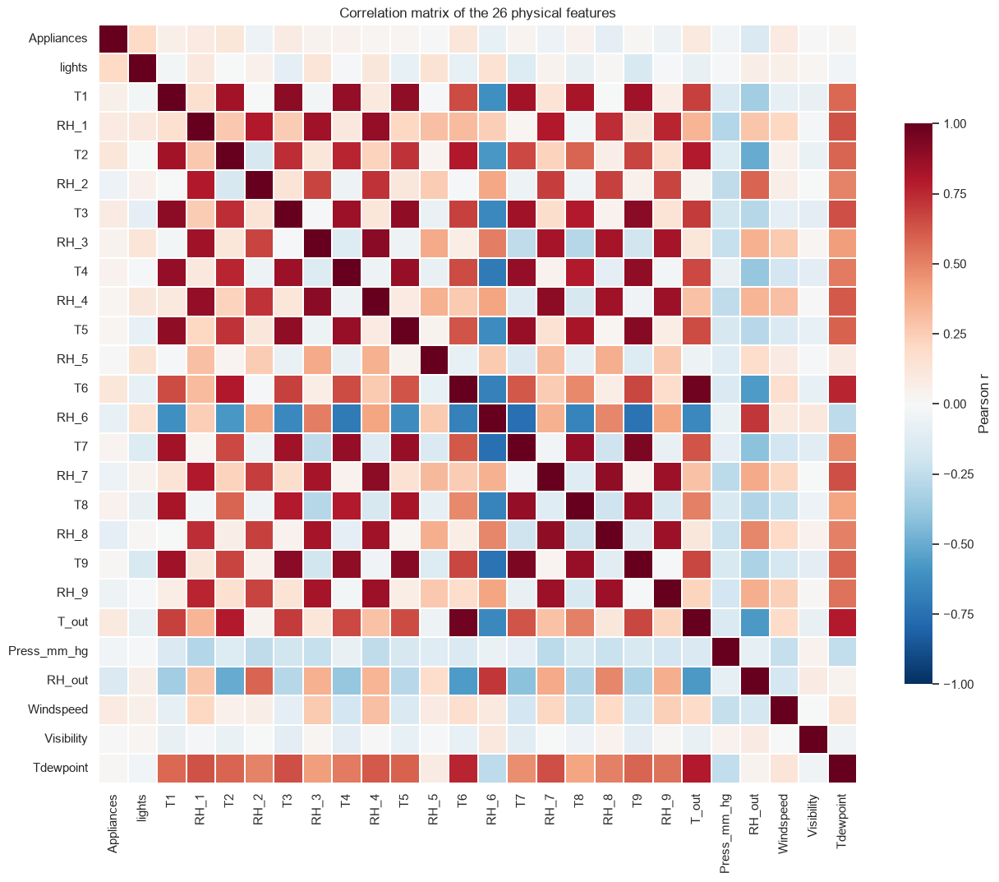

Pairs with |r| > 0.9: 4 | |r| > 0.8: 35 (out of 325)


,,r
T6,T_out,0.975
T7,T9,0.945
T5,T9,0.911
T3,T9,0.901
RH_3,RH_4,0.899
RH_4,RH_7,0.894
T1,T3,0.892
T4,T9,0.889
T3,T5,0.888
T1,T5,0.885


Correlation of each feature with Appliances (top 6 by |r|):


,Appliances
lights,0.197
RH_out,-0.152
T2,0.120
T6,0.118
T_out,0.099
RH_8,-0.094


In [8]:
MODEL_FEATURES = [c for c in df.columns if c not in ("date", "rv1", "rv2")]
corr = df[MODEL_FEATURES].corr()

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.3, cbar_kws={"shrink": 0.7, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation matrix of the 26 physical features")
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna().rename("r")
top_pairs = upper.reindex(upper.abs().sort_values(ascending=False).index)
print(f"Pairs with |r| > 0.9: {(upper.abs() > 0.9).sum()} | |r| > 0.8: {(upper.abs() > 0.8).sum()} "
      f"(out of {len(upper)})")
display(top_pairs.head(12).to_frame())
print("Correlation of each feature with Appliances (top 6 by |r|):")
display(corr["Appliances"].drop("Appliances").sort_values(key=abs, ascending=False).head(6).to_frame())

### 2.5 Distribution analysis

Each feature gets a histogram with a kernel density estimate, and each subplot title reports its skewness. The histograms show the shape of each distribution, including modality, skew and discreteness.

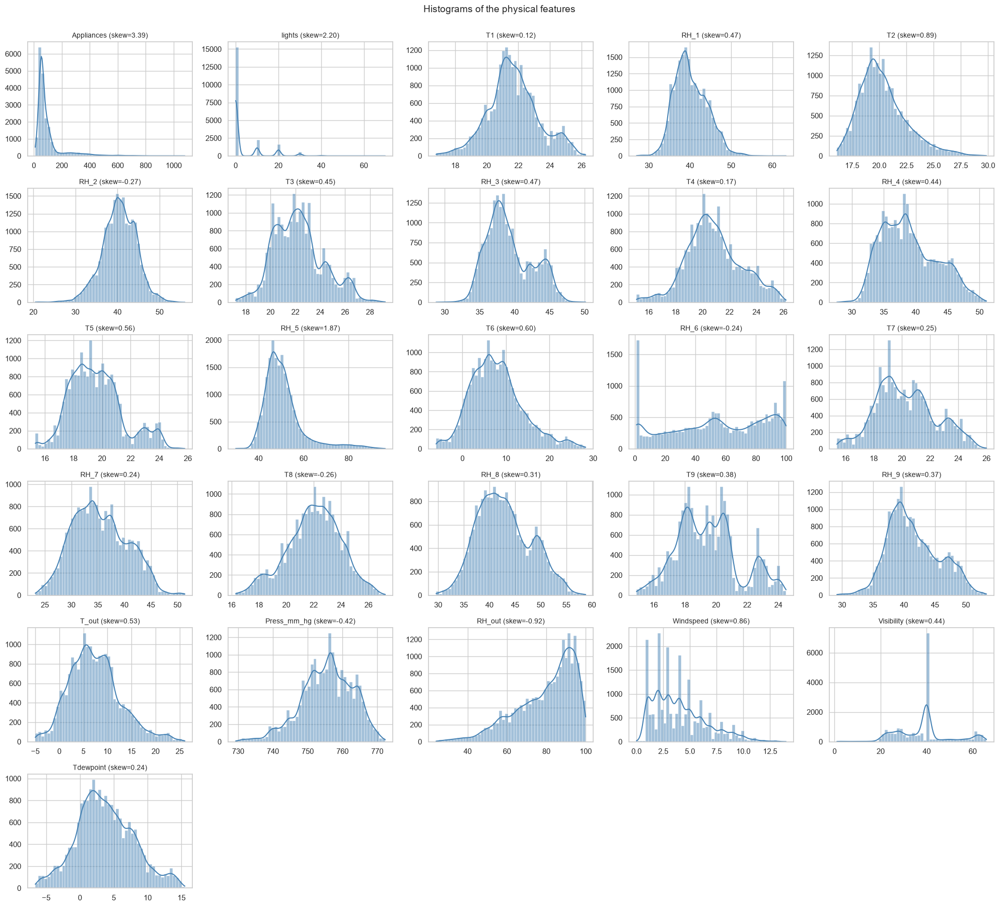

In [9]:
def plot_feature_grid(data, features, kind, n_cols=5, title=""):
    """Draw one small histogram or boxplot per feature in a grid."""
    n_rows = int(np.ceil(len(features) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
    axes = axes.ravel()
    for ax, col in zip(axes, features):
        if kind == "hist":
            sns.histplot(data[col], bins=50, kde=True, ax=ax, color="steelblue")
            ax.set_title(f"{col} (skew={data[col].skew():.2f})", fontsize=10)
        else:
            sns.boxplot(x=data[col], ax=ax, color="lightsteelblue", fliersize=1.5)
            ax.set_title(col, fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("")
    for ax in axes[len(features):]:
        ax.remove()
    fig.suptitle(title, fontsize=14, y=1.0)
    plt.tight_layout()
    plt.show()

plot_feature_grid(df, MODEL_FEATURES, "hist", title="Histograms of the physical features")

Boxplots complement the histograms. Points beyond the whiskers ($Q_1 - 1.5\,\mathrm{IQR}$, $Q_3 + 1.5\,\mathrm{IQR}$) are the candidates for univariate outliers.

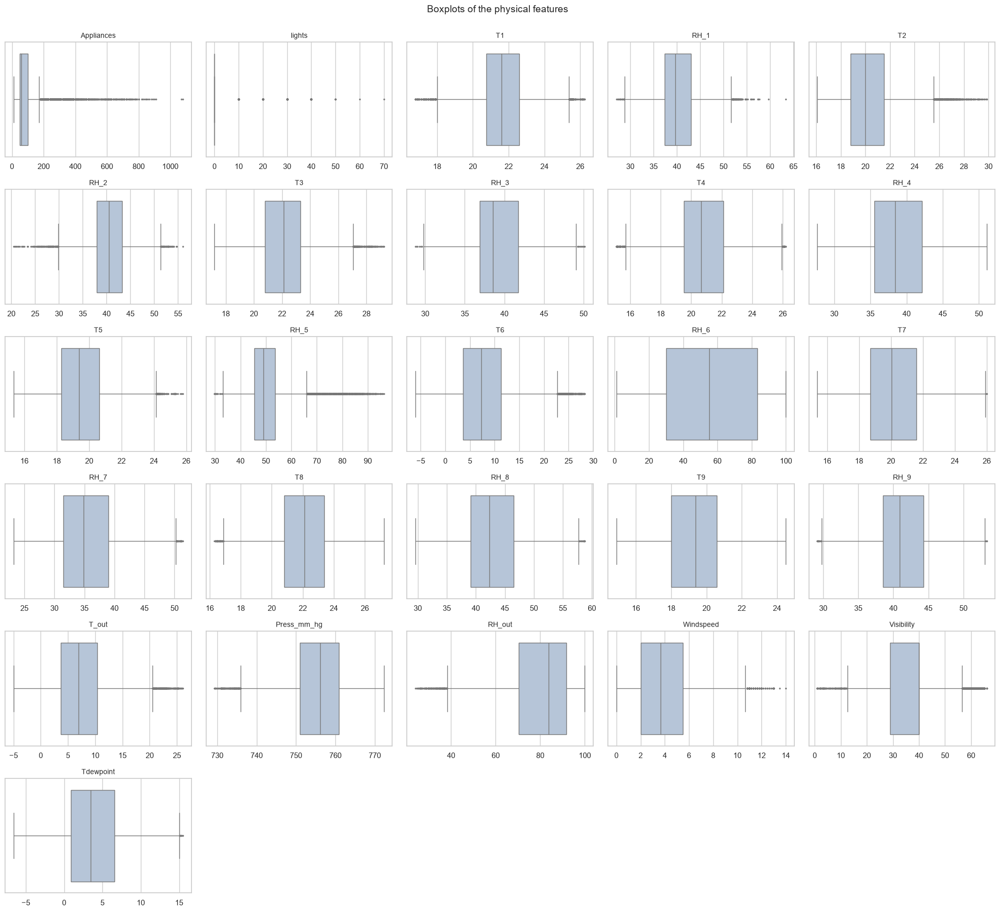

In [10]:
plot_feature_grid(df, MODEL_FEATURES, "box", title="Boxplots of the physical features")

**Skewness** $\gamma_1 = E[(x-\mu)^3]/\sigma^3$ measures asymmetry. **Excess kurtosis** $\gamma_2 = E[(x-\mu)^4]/\sigma^4 - 3$ measures tail heaviness relative to a Gaussian, which has $\gamma_2 = 0$. The table also reports the percentage of IQR outliers per feature.

In [11]:
def iqr_outlier_share(series):
    """Percentage of values outside the Tukey fences Q1 - 1.5 IQR, Q3 + 1.5 IQR."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return 100 * ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).mean()

dist_stats = pd.DataFrame({
    "skewness": df[MODEL_FEATURES].apply(stats.skew),
    "excess_kurtosis": df[MODEL_FEATURES].apply(stats.kurtosis),
    "iqr_outliers_%": df[MODEL_FEATURES].apply(iqr_outlier_share),
}).sort_values("skewness", key=abs, ascending=False)
display(dist_stats.round(2))

,skewness,excess_kurtosis,iqr_outliers_%
Appliances,3.390,13.660,10.830
lights,2.190,4.460,22.720
RH_5,1.870,4.500,6.740
RH_out,-0.920,0.260,1.210
T2,0.890,0.930,2.770
Windspeed,0.860,0.250,1.080
T6,0.600,0.430,2.610
T5,0.560,0.110,0.910
T_out,0.530,0.360,2.210
RH_3,0.470,-0.580,0.080


### 2.6 Temporal context

The rows form a time series. Two views help interpret everything that follows:

- **Daily means (left panel).** These reveal the seasonal drift from January to May.
- **Hour-of-day profile of `Appliances` (right panel).** This reveals the household routine.

A clustering or anomaly detector that simply rediscovers the season or the time of day is an important possibility to keep in mind.

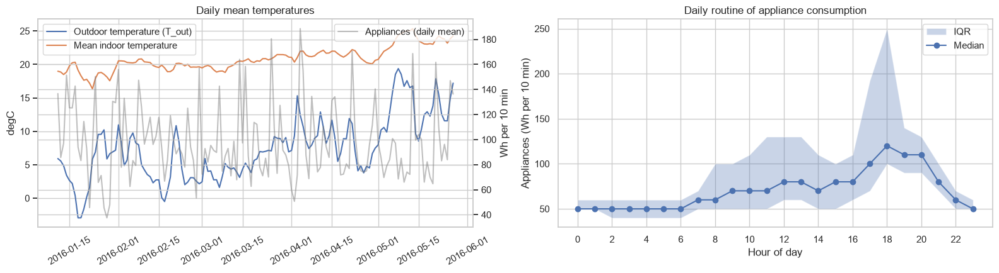

In [12]:
indoor_temp_cols = [f"T{i}" for i in ROOMS if i != 6]
daily = df.set_index("date").resample("D").agg({"T_out": "mean", "Appliances": "mean"})
daily["T_indoor_mean"] = df.set_index("date")[indoor_temp_cols].mean(axis=1).resample("D").mean()
hourly = df.groupby(df["date"].dt.hour)["Appliances"].quantile([0.25, 0.5, 0.75]).unstack()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(daily.index, daily["T_out"], label="Outdoor temperature (T_out)")
axes[0].plot(daily.index, daily["T_indoor_mean"], label="Mean indoor temperature")
axes[0].set_ylabel("degC")
axes[0].set_title("Daily mean temperatures")
axes[0].legend(loc="upper left")
axes[0].tick_params(axis="x", rotation=30)
ax_twin = axes[0].twinx()
ax_twin.plot(daily.index, daily["Appliances"], color="grey", alpha=0.5, label="Appliances (daily mean)")
ax_twin.set_ylabel("Wh per 10 min")
ax_twin.legend(loc="upper right")

axes[1].fill_between(hourly.index, hourly[0.25], hourly[0.75], alpha=0.3, label="IQR")
axes[1].plot(hourly.index, hourly[0.5], marker="o", label="Median")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Appliances (Wh per 10 min)")
axes[1].set_title("Daily routine of appliance consumption")
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend()
plt.tight_layout()
plt.show()

### 2.7 Outlier exploration: tails, artifacts and data-entry issues

The checks below quantify the specific phenomena behind the unusual values:

- **Measurement resolution.** Meters report in fixed steps, which makes some variables discrete.
- **Sensor limits.** The outdoor humidity sensor `RH_6` piles up at the physical limits of its range.
- **Behavioural spikes.** Bathroom humidity `RH_5` spikes at specific hours.
- **Local sensor versus weather station.** The outdoor sensor `T6` is compared with the airport temperature `T_out`.
- **Interpolation of the weather data.** A zero second difference means a straight-line segment, which is the signature of linear interpolation.
- **Default values.** `Visibility` repeats one value unusually often.
- **Extreme consumption.** A small number of intervals have very high appliance usage.

In [13]:
artifact_checks = pd.Series({
    "lights == 0 (share of rows)": (df["lights"] == 0).mean(),
    "lights values that are multiples of 10 (share)": (df["lights"] % 10 == 0).mean(),
    "Appliances values that are multiples of 10 (share)": (df["Appliances"] % 10 == 0).mean(),
    "Appliances > 500 Wh (rows)": (df["Appliances"] > 500).sum(),
    "Appliances 99th percentile (Wh)": df["Appliances"].quantile(0.99),
    "RH_6 == 1.0% exactly (rows, sensor floor)": (df["RH_6"] == 1.0).sum(),
    "RH_out mean when RH_6 <= 2%": df.loc[df["RH_6"] <= 2, "RH_out"].mean(),
    "RH_6 >= 99% (rows, sensor ceiling)": (df["RH_6"] >= 99).sum(),
    "RH_5 > 80% (rows, bathroom)": (df["RH_5"] > 80).sum(),
    "RH_5 > 80%: share occurring 19:00-22:59": df.loc[df["RH_5"] > 80, "date"].dt.hour.between(19, 22).mean(),
    "max (T6 - T_out) degC": (df["T6"] - df["T_out"]).max(),
    "T_out: share of zero 2nd differences (linear interpolation)":
        np.isclose(df["T_out"].diff().diff(), 0).mean(),
    "Visibility == 40 km (share of rows)": (df["Visibility"] == 40).mean(),
}, name="value")
display(artifact_checks.round(3).to_frame())

rh6_floor_months = df.loc[df["RH_6"] <= 2, "date"].dt.month.value_counts().sort_index()
print("Months in which RH_6 sits at its floor:", rh6_floor_months.to_dict())

,value
lights == 0 (share of rows),0.773
lights values that are multiples of 10 (share),1.000
Appliances values that are multiples of 10 (share),1.000
Appliances > 500 Wh (rows),288.000
Appliances 99th percentile (Wh),576.600
"RH_6 == 1.0% exactly (rows, sensor floor)",1452.000
RH_out mean when RH_6 <= 2%,50.649
"RH_6 >= 99% (rows, sensor ceiling)",922.000
"RH_5 > 80% (rows, bathroom)",461.000
RH_5 > 80%: share occurring 19:00-22:59,0.586


Months in which RH_6 sits at its floor: {4: 315, 5: 1291}


**EDA summary.**

- **Structure.** The data are complete and regularly sampled: no missing values, no duplicates and no gaps in the 10-minute grid.
- **Redundancy.** The correlation matrix contains two large blocks: indoor temperatures (pairwise $r$ up to 0.95) and indoor humidities. The outdoor sensor `T6` is almost a copy of the station temperature `T_out` ($r = 0.975$). Of the 325 feature pairs, 35 have $|r| > 0.8$. By contrast, `Appliances` correlates only weakly with every other variable ($|r| < 0.2$). Consumption is driven by behaviour, not by the indoor climate.
- **Heavy tails.**
  - `Appliances` is extremely right-skewed (skewness 3.4, excess kurtosis 13.7). The median is 60 Wh, but the maximum is 1,080 Wh, and 10.8% of values are IQR outliers.
  - `lights` is zero-inflated: it is 0 in 77% of rows.
  - `RH_5` (bathroom) has sharp spikes above 80%, concentrated in the evening. This is the signature of showers.
- **Measurement artifacts.**
  - **Humidity floor on the outdoor sensor.** `RH_6` sits at *exactly* 1.0% in 1,452 rows, almost all on April–May afternoons, while the weather station reports ≈50% humidity at the same times. That is a sensor floor, not a physical state.
  - **Linear interpolation.** 85% of consecutive second differences of `T_out` are zero, confirming that the hourly weather data were linearly interpolated to 10-minute steps.
  - **Default visibility value.** `Visibility` takes the value 40 km in 37% of rows, which looks like a reporting default. The 12.8% "IQR outliers" of this feature are therefore an artifact of that spike, not genuine extremes.
- **Data entry.** No impossible values (such as negative energy or humidity above 100%) were found. Consumption is recorded in steps of 10 Wh, so it is discrete.
- **Decision.** The extreme values are mostly physically plausible events: cooking, laundry, showers. Removing them would delete exactly the behaviour that anomaly detection should find, so **no rows are dropped**. The `RH_6` floor is kept as well, and it is later used to check whether the detectors notice a known artifact.

### 2.8 Preprocessing for the unsupervised analysis

Each choice below is made once and shared by every later section:

1. **Feature selection.** Keep the 26 physical features. Drop `date` (used only for interpretation) and the random controls `rv1` and `rv2`.
2. **Log transform of `Appliances`.** Replace it with $\log(1+x)$. A skewness above 3 would let a handful of peaks dominate every variance- and distance-based method. The transform keeps the order of the values but compresses the tail.
3. **Standardisation.** Transform each feature as $z = (x-\mu)/\sigma$. Features are measured in incompatible units (°C, %, mm Hg, Wh), and PCA, k-means, DBSCAN and LOF are all scale dependent.

Time attributes (hour, weekday, month) are kept in a separate `meta` table. They are **not** used by any algorithm. Their only role is to interpret the results afterwards.

In [14]:
X_raw = df[MODEL_FEATURES].astype(float).copy()
X_raw["Appliances"] = np.log1p(X_raw["Appliances"])
X_raw = X_raw.rename(columns={"Appliances": "log_Appliances"})
FEATURES = X_raw.columns.tolist()

scaler = StandardScaler()
X = scaler.fit_transform(X_raw)
X_df = pd.DataFrame(X, columns=FEATURES)

meta = pd.DataFrame({"date": df["date"],
                     "hour": df["date"].dt.hour,
                     "weekday": df["date"].dt.dayofweek,
                     "month": df["date"].dt.month,
                     "Appliances": df["Appliances"]})

print(f"Model matrix X: {X.shape[0]:,} samples x {X.shape[1]} features")
print(f"Skewness of Appliances: raw {df['Appliances'].skew():.2f} -> log {X_raw['log_Appliances'].skew():.2f}")

Model matrix X: 19,735 samples x 26 features
Skewness of Appliances: raw 3.39 -> log 1.19


## 3. Dimensionality Reduction

### 3.1 Principal Component Analysis (PCA)

**Intuition.** PCA finds orthogonal directions of maximal variance. For the standardised data matrix $X$, it diagonalises the sample covariance matrix, which here equals the correlation matrix:

$$
C = \tfrac{1}{n} X^\top X = V \Lambda V^\top .
$$

- The eigenvectors $v_j$ (the **loadings**) define the principal components.
- The eigenvalues $\lambda_j$ are the variances those components capture.
- The explained-variance ratio of component $j$ is $\lambda_j / \sum_k \lambda_k$.

Keeping the first $k$ components gives the best rank-$k$ linear approximation of $X$ in the least-squares sense. The fraction of variance lost is $1 - \sum_{j \le k}\lambda_j / \sum_j \lambda_j$.

**Assumptions.** The relevant structure is linear and captured by second moments, and high variance is equated with importance.

In [15]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
evr = pca.explained_variance_ratio_
cum_evr = np.cumsum(evr)

pca_table = pd.DataFrame({"eigenvalue": pca.explained_variance_,
                          "explained_var_ratio": evr,
                          "cumulative": cum_evr},
                         index=[f"PC{i + 1}" for i in range(len(evr))])
display(pca_table.head(12))

n_components_for = {t: int(np.searchsorted(cum_evr, t) + 1) for t in (0.80, 0.90, 0.95, 0.99)}
print("Components needed for a given share of variance:", n_components_for)
print("Kaiser criterion (eigenvalue > 1):", int((pca.explained_variance_ > 1).sum()), "components")

,eigenvalue,explained_var_ratio,cumulative
PC1,9.355,0.360,0.360
PC2,7.068,0.272,0.632
PC3,1.882,0.072,0.704
PC4,1.348,0.052,0.756
PC5,1.044,0.040,0.796
PC6,0.982,0.038,0.834
PC7,0.882,0.034,0.868
PC8,0.689,0.027,0.894
PC9,0.557,0.021,0.916
PC10,0.519,0.020,0.936


Components needed for a given share of variance: {0.8: 6, 0.9: 9, 0.95: 12, 0.99: 19}
Kaiser criterion (eigenvalue > 1): 5 components


**Scree plot.** The bars show the variance of each component, and the line shows the cumulative share. The "elbow" (the point after which additional components add little) and the 90% threshold are the two standard guides for choosing $k$.

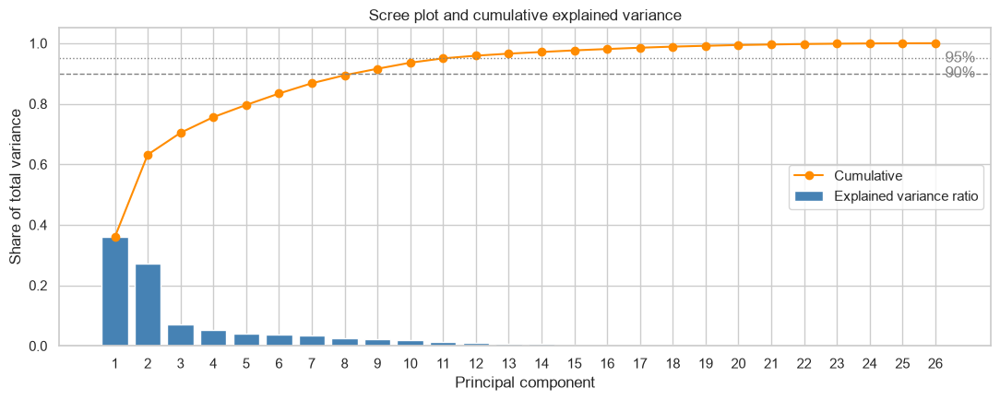

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.5))
pcs = np.arange(1, len(evr) + 1)
ax.bar(pcs, evr, color="steelblue", label="Explained variance ratio")
ax.plot(pcs, cum_evr, color="darkorange", marker="o", label="Cumulative")
for threshold, style in [(0.90, "--"), (0.95, ":")]:
    ax.axhline(threshold, color="grey", linestyle=style, linewidth=1)
    ax.text(len(evr) + 0.3, threshold, f"{threshold:.0%}", va="center", color="grey")
ax.set_xticks(pcs)
ax.set_xlabel("Principal component")
ax.set_ylabel("Share of total variance")
ax.set_title("Scree plot and cumulative explained variance")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

**Information loss and redundancy.**

- **Information loss.** For standardised data, the information lost by keeping $k$ components equals the mean squared reconstruction error per feature. The code verifies this numerically.
- **Participation ratio.** Defined as $(\sum\lambda)^2/\sum\lambda^2$, it summarises the *effective* number of dimensions.
- **Condition number.** The condition number of the correlation matrix quantifies how close the original features are to being linearly dependent.

In [17]:
def pca_information_loss(k):
    """Share of variance lost and reconstruction MSE when keeping the first k components."""
    reconstruction = pca.transform(X)[:, :k] @ pca.components_[:k] + pca.mean_
    return 1 - cum_evr[k - 1], np.mean((X - reconstruction) ** 2)

N_PCA = n_components_for[0.90]
for k in (2, 3, N_PCA):
    lost, mse = pca_information_loss(k)
    print(f"k = {k:2d}: variance lost = {lost:6.1%} | reconstruction MSE = {mse:.3f}")

eigenvalues = pca.explained_variance_
participation_ratio = eigenvalues.sum() ** 2 / (eigenvalues ** 2).sum()
print(f"\nParticipation ratio (effective dimensionality): {participation_ratio:.1f} of {X.shape[1]}")
print(f"Condition number of the correlation matrix   : {np.linalg.cond(np.corrcoef(X, rowvar=False)):,.0f}")

k =  2: variance lost =  36.8% | reconstruction MSE = 0.368
k =  3: variance lost =  29.6% | reconstruction MSE = 0.296
k =  9: variance lost =   8.4% | reconstruction MSE = 0.084

Participation ratio (effective dimensionality): 4.6 of 26
Condition number of the correlation matrix   : 2,529


**Loadings.** Each cell shows the weight of an original feature in a component. Features with large absolute loadings of the same sign move together along that component. The printed lists give the dominant contributors to each component.

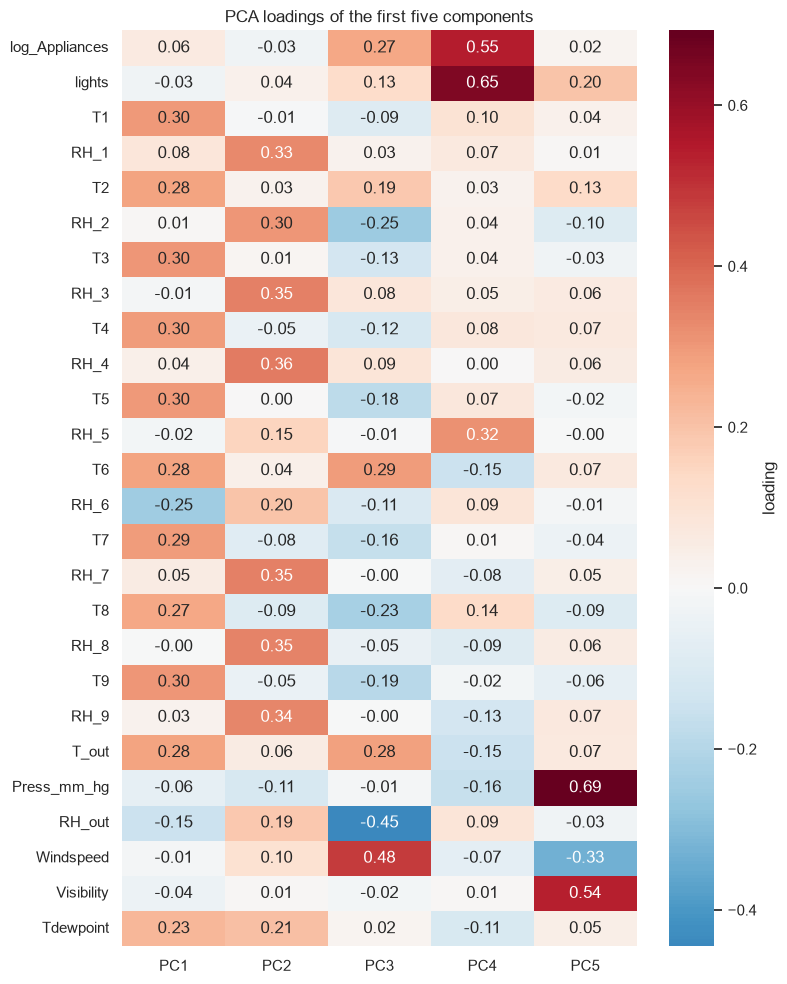

PC1 (36.0%): T9 (+0.30), T3 (+0.30), T1 (+0.30), T5 (+0.30), T4 (+0.30)
PC2 (27.2%): RH_4 (+0.36), RH_3 (+0.35), RH_7 (+0.35), RH_8 (+0.35), RH_9 (+0.34)
PC3 (7.2%): Windspeed (+0.48), RH_out (-0.45), T6 (+0.29), T_out (+0.28), log_Appliances (+0.27)
PC4 (5.2%): lights (+0.65), log_Appliances (+0.55), RH_5 (+0.32), Press_mm_hg (-0.16), T_out (-0.15)
PC5 (4.0%): Press_mm_hg (+0.69), Visibility (+0.54), Windspeed (-0.33), lights (+0.20), T2 (+0.13)


In [18]:
N_SHOW = 5
loadings = pd.DataFrame(pca.components_[:N_SHOW].T, index=FEATURES,
                        columns=[f"PC{i + 1}" for i in range(N_SHOW)])

fig, ax = plt.subplots(figsize=(8, 10))
sns.heatmap(loadings, cmap="RdBu_r", center=0, annot=True, fmt=".2f",
            cbar_kws={"label": "loading"}, ax=ax)
ax.set_title("PCA loadings of the first five components")
plt.tight_layout()
plt.show()

for pc in loadings.columns:
    top = loadings[pc].abs().nlargest(5).index
    print(f"{pc} ({evr[int(pc[2:]) - 1]:.1%}): " + ", ".join(f"{f} ({loadings.loc[f, pc]:+.2f})" for f in top))

**2D projection.** Every observation is projected onto PC1–PC2. The left panel colours points by month (known context that PCA never saw), and the right panel colours them by log appliance consumption.

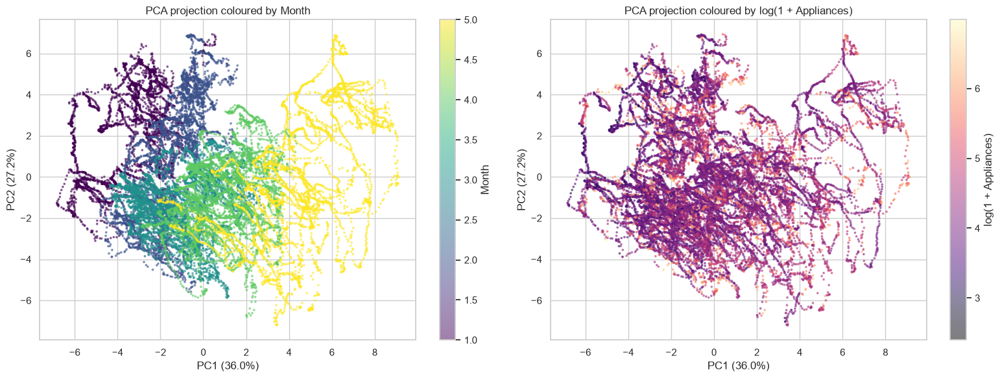

In [19]:
Z_all = pca.transform(X)          # all 26 component scores
Z = Z_all[:, :N_PCA]              # reduced representation (90% variance) used for clustering

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, values, cmap, label in [
        (axes[0], meta["month"], "viridis", "Month"),
        (axes[1], X_raw["log_Appliances"], "magma", "log(1 + Appliances)")]:
    points = ax.scatter(Z_all[:, 0], Z_all[:, 1], c=values, cmap=cmap, s=3, alpha=0.5)
    fig.colorbar(points, ax=ax, label=label)
    ax.set_xlabel(f"PC1 ({evr[0]:.1%})")
    ax.set_ylabel(f"PC2 ({evr[1]:.1%})")
    ax.set_title(f"PCA projection coloured by {label}")
plt.tight_layout()
plt.show()

**3D projection.** This interactive view adds PC3 and can be rotated to inspect the geometry. It uses a random subsample of 6,000 points to keep rendering responsive.

In [20]:
idx_3d = rng.choice(len(X), size=6000, replace=False)
fig = px.scatter_3d(x=Z_all[idx_3d, 0], y=Z_all[idx_3d, 1], z=Z_all[idx_3d, 2],
                    color=meta["month"].iloc[idx_3d].astype(str),
                    labels={"x": "PC1", "y": "PC2", "z": "PC3", "color": "Month"},
                    opacity=0.6, title="PCA projection into 3D (coloured by month)",
                    category_orders={"color": ["1", "2", "3", "4", "5"]})
fig.update_traces(marker_size=2)
fig.update_layout(height=600)
fig.show()

**Stability of the components.** Two tests check whether the components are artefacts of this particular sample:

1. **Bootstrap test.** Fit PCA on 20 bootstrap resamples.
2. **Temporal test.** Fit PCA separately on the first and second half of the period.

For each full-data component, the code reports the absolute cosine similarity with the **best-matching** component of the refitted PCA, among its first five. This allows components to swap order. A value of 1 means an identical direction.

In [21]:
def component_similarity(X_subset, n=3, search=5):
    """For each of the first n full-data loadings: max |cosine| with any of the first `search` refitted loadings."""
    components = PCA(n_components=search).fit(X_subset).components_
    return np.abs(pca.components_[:n] @ components.T).max(axis=1)

bootstrap_sims = np.array([component_similarity(X[rng.choice(len(X), len(X), replace=True)])
                           for _ in range(20)])
half = len(X) // 2
stability = pd.DataFrame({
    "bootstrap mean": bootstrap_sims.mean(axis=0),
    "bootstrap min": bootstrap_sims.min(axis=0),
    "first half (Jan-Mar)": component_similarity(X[:half]),
    "second half (Mar-May)": component_similarity(X[half:]),
}, index=["PC1", "PC2", "PC3"])
display(stability)

,bootstrap mean,bootstrap min,first half (Jan-Mar),second half (Mar-May)
PC1,0.999,0.997,0.832,0.778
PC2,0.999,0.997,0.980,0.648
PC3,0.999,0.999,0.507,0.813


### 3.2 Local versus global structure: PCA compared with t-SNE

PCA is a **global, linear** method: it preserves large distances and overall variance. t-SNE is a **local, non-linear** method, which works as follows:

- It converts pairwise distances into neighbourhood probabilities, using a Gaussian kernel in the original space and a heavy-tailed Student-t kernel in the embedding.
- It then minimises the KL divergence between the two distributions.

As a result, t-SNE preserves who is near whom, but distances *between* groups, cluster sizes and densities in the embedding are not meaningful. Both methods are applied to the same 3,000-point subsample, and both are timed.

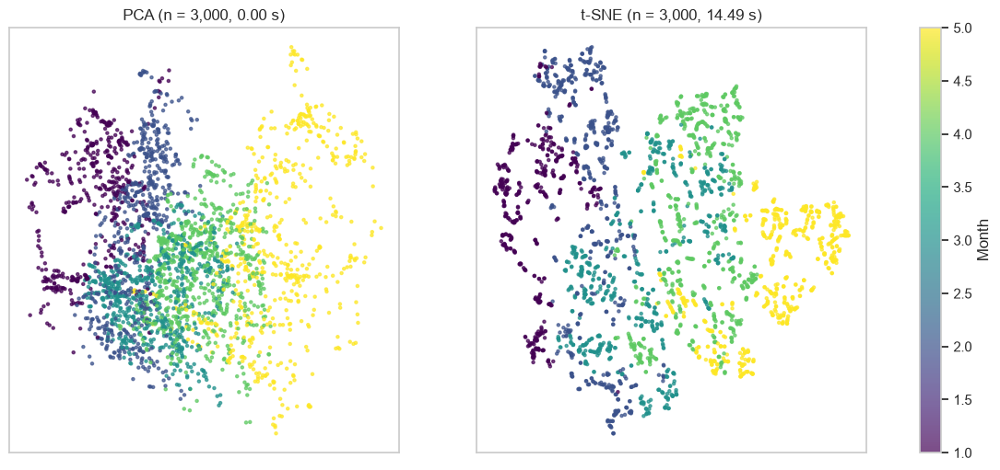

Runtime ratio t-SNE / PCA: 5,481x


In [22]:
idx_tsne = rng.choice(len(X), size=3000, replace=False)

start = time.perf_counter()
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X[idx_tsne])
time_pca = time.perf_counter() - start

start = time.perf_counter()
tsne_2d = TSNE(n_components=2, perplexity=30, init="pca",
               random_state=RANDOM_STATE).fit_transform(X[idx_tsne])
time_tsne = time.perf_counter() - start

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, emb, name, seconds in [(axes[0], pca_2d, "PCA", time_pca), (axes[1], tsne_2d, "t-SNE", time_tsne)]:
    points = ax.scatter(emb[:, 0], emb[:, 1], c=meta["month"].iloc[idx_tsne], cmap="viridis", s=5, alpha=0.7)
    ax.set_title(f"{name} (n = 3,000, {seconds:.2f} s)")
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(points, ax=axes, label="Month")
plt.show()
print(f"Runtime ratio t-SNE / PCA: {time_tsne / time_pca:,.0f}x")

### 3.3 Discussion of the dimensionality reduction

**How many components are needed?** There is no single answer. Four criteria point to different values:

| Criterion | Components |
|---|---|
| Elbow of the scree plot | 2 |
| Kaiser rule ($\lambda>1$) | 5 |
| 90% of the variance | 9 |
| 95% of the variance | 12 |

The last two are out of 26 features. For analysis, **9 components (90%)** are a reasonable compromise and are used for clustering. For visualisation, 2–3 components are used, while acknowledging that they lose 30–37% of the variance.

**Information lost.** The fraction of variance lost is 36.8% with 2 components, 29.6% with 3 and 8.4% with 9. It equals the reconstruction MSE on the standardised data, as the code verifies. The discarded components are not necessarily noise: PC4 alone (5%) carries most of the consumption signal.

**Correlation and its effect on PCA.** The indoor temperatures are strongly inter-correlated, and so are the indoor humidities; `T6` and `T_out` are nearly identical ($r=0.975$). PCA collapses each block into one component:

- **PC1 (36%)** loads almost equally (+0.30) on all temperatures, indoor and outdoor. It is a *thermal state / season* axis.
- **PC2 (27%)** loads on all indoor humidities. It is a *moisture* axis.
- **PC3 (7%)** contrasts wind speed with outdoor humidity. It captures *weather type*: windy and dry versus calm and humid.
- **PC4 (5%)** is the only *behavioural* component: `lights`, `log_Appliances` and bathroom humidity `RH_5`. It captures occupant activity.
- **PC5 (4%)** combines pressure and visibility: *synoptic weather*.

A practical consequence follows. Because the climate blocks contain many correlated sensors, they dominate the variance. The quantity of original interest, energy consumption, appears only in the fourth component. **Variance is not the same as relevance.**

**Is the reduced representation more effective?** For geometry-based methods, yes:

- The participation ratio is 4.6, so the 26 features behave like about 5 effective dimensions.
- The condition number of the correlation matrix is ≈2,500, which indicates strong multicollinearity.
- Nine uncorrelated components retain 92% of the variance with none of the double counting.

The price is interpretability: each component mixes many sensors, and anomalies that live in low-variance directions can be discarded (see Section 7.3).

**Local versus global structure; cluster separation.**

- **PCA** shows a smooth, continuous seasonal gradient along PC1 (January→May) without gaps. There is no visible cluster separation.
- **t-SNE** preserves the same month ordering, but fragments it into many short, elongated strands. These strands are **runs of consecutive time stamps**: each 10-minute reading is a near-duplicate of its neighbours in time, so t-SNE's local neighbourhoods are dominated by temporal autocorrelation. They are not genuine groups. The apparent gaps between strands must not be read as cluster structure, and distances between them are meaningless.

**Stability.**

- Under **bootstrap resampling**, PCA is essentially perfectly stable ($|\cos| > 0.99$).
- Fitting it separately on the **first versus the second half** of the period changes the components noticeably ($|\cos|$ as low as 0.51–0.65). The correlation structure is **non-stationary**: the relationship between indoor and outdoor climate differs between heating season and spring.

**Computational cost.** PCA is a single SVD, $O(nd^2)$, and effectively instantaneous. t-SNE is iterative, $O(n \log n)$ per iteration with Barnes–Hut, and on only 3,000 points it was several thousand times slower. It also cannot project new points.

**Interpretability.** PCA gives an explicit linear map (the loadings) that can be read physically, as done above. t-SNE axes carry no meaning.

## 4. Clustering Analysis

All sample-level clustering is performed on the **PCA representation that retains 90% of the variance** (`Z`, built in Section 3.1):

- It removes redundant, highly collinear directions, which would otherwise count the same physical effect several times in Euclidean distances.
- It discards low-variance directions that are mostly noise.
- It reduces the cost of neighbourhood-based methods.

### 4.1 Evaluation metric

The assignment proposes comparing **the average variance within each cluster with the global variance**:

$$
\rho = \frac{\sum_c \tfrac{n_c}{n}\,\operatorname{tr}\,\Sigma_c}{\operatorname{tr}\,\Sigma}
      = \frac{W}{T} = 1 - R^2 ,
$$

where $W$ is the within-cluster sum of squares and $T$ is the total sum of squares.

**Suitability.** $\rho$ is a useful measure of compactness, but it is **not sufficient for choosing a model**, for three reasons:

1. It decreases monotonically as the number of clusters grows, reaching 0 when every point is its own cluster.
2. It implicitly assumes compact, spherical clusters, so it favours k-means by construction.
3. It says nothing about *separation* between clusters, and it is undefined for DBSCAN's noise points.

It is therefore reported together with three alternatives:

- **Silhouette coefficient** $s = (b-a)/\max(a,b)$, where $a$ is the mean distance to the point's own cluster and $b$ the mean distance to the nearest other cluster. It combines cohesion and separation and is bounded in $[-1,1]$.
- **Davies–Bouldin index** (lower is better).
- **Calinski–Harabasz index** (higher is better).

In [23]:
def cluster_report(Z_data, labels, method, sample_size=5000):
    """Compactness and separation metrics; points labelled -1 (DBSCAN noise) are excluded."""
    labels = np.asarray(labels)
    mask = labels != -1
    Z_m, l_m = Z_data[mask], labels[mask]
    clusters, sizes = np.unique(l_m, return_counts=True)
    global_var = Z_m.var(axis=0).sum()
    within_var = np.array([Z_m[l_m == c].var(axis=0).sum() for c in clusters])
    report = {"method": method,
              "n_clusters": len(clusters),
              "noise_%": 100 * (~mask).mean(),
              "largest_cluster_%": 100 * sizes.max() / len(labels),
              "mean within/global var": (within_var / global_var).mean(),
              "weighted within/global var (W/T)": (sizes * within_var).sum() / sizes.sum() / global_var}
    if len(clusters) > 1:
        report["silhouette"] = silhouette_score(Z_m, l_m, sample_size=min(sample_size, mask.sum()),
                                                random_state=RANDOM_STATE)
        report["davies_bouldin"] = davies_bouldin_score(Z_m, l_m)
        report["calinski_harabasz"] = calinski_harabasz_score(Z_m, l_m)
    return report

### 4.2 K-Means

**Intuition.** K-Means partitions the data into $k$ groups by minimising the within-cluster sum of squares

$$
\min_{\{C_c\},\{\mu_c\}} \sum_{c=1}^{k}\sum_{x_i\in C_c}\lVert x_i-\mu_c\rVert^2 .
$$

Lloyd's algorithm alternates two steps: assign each point to the nearest centroid, then move each centroid to the mean of its points. Each step can only decrease the objective, so the algorithm converges to a *local* optimum. It is therefore restarted from several initialisations (`n_init`).

**Assumptions.** Clusters are convex, roughly spherical and of similar size and variance. $k$ must be known in advance, and every point is forced into some cluster.

**Strengths.** It is fast (linear in $n$), simple and gives interpretable centroids.

**Weaknesses.** It is sensitive to scale, outliers and initialisation, and it fails on elongated, nested or density-defined shapes.

**Choosing $k$.** Three diagnostics are compared across $k = 2,\dots,10$: the elbow of the inertia curve, the silhouette score and the ratio $W/T$.

,inertia,W/T,silhouette
k,,,
2,345538.732,0.735,0.247
3,271291.382,0.577,0.251
4,235600.965,0.501,0.221
5,211851.882,0.451,0.215
6,195021.118,0.415,0.200
7,184695.780,0.393,0.188
8,176579.386,0.376,0.188
9,168696.262,0.359,0.175
10,162197.551,0.345,0.173


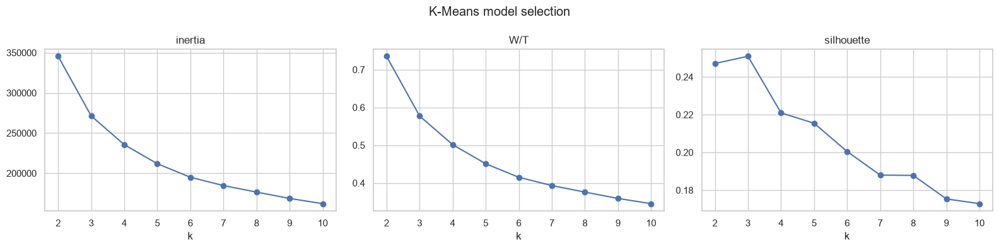

In [24]:
kmeans_diag = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    kmeans_diag.append({"k": k,
                        "inertia": km.inertia_,
                        "W/T": km.inertia_ / (len(Z) * Z.var(axis=0).sum()),
                        "silhouette": silhouette_score(Z, km.labels_, sample_size=5000,
                                                       random_state=RANDOM_STATE)})
kmeans_diag = pd.DataFrame(kmeans_diag).set_index("k")
display(kmeans_diag)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["inertia", "W/T", "silhouette"]):
    ax.plot(kmeans_diag.index, kmeans_diag[col], marker="o")
    ax.set_xlabel("k")
    ax.set_title(col)
fig.suptitle("K-Means model selection")
plt.tight_layout()
plt.show()

**Choice of $k$.**

- **Inertia and $W/T$.** Both decrease smoothly, with the largest drops at $k=3$ and $k=4$, but there is no sharp elbow.
- **Silhouette.** It is highest at **$k=3$ (0.251)**, marginally above $k=2$ (0.247), and declines steadily afterwards.
- **Decision.** $k=3$ is selected.
- **Caveat.** A silhouette of ≈0.25 indicates **weak, overlapping structure**. By common rules of thumb, values below 0.25–0.3 suggest no substantial cluster structure, so the partition should be read as a useful *segmentation* of a continuum rather than as the discovery of natural groups.

In [25]:
K_CHOSEN = 3
kmeans = KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=RANDOM_STATE).fit(Z)
kmeans_labels = kmeans.labels_
display(pd.DataFrame([cluster_report(Z, kmeans_labels, f"K-Means (k={K_CHOSEN})")]).set_index("method"))

,n_clusters,noise_%,largest_cluster_%,mean within/global var,weighted within/global var (W/T),silhouette,davies_bouldin,calinski_harabasz
method,,,,,,,,
K-Means (k=3),3,0.000,47.307,0.591,0.577,0.251,1.347,7219.647


**Stability.** Two perturbations test whether the partition is a property of the data or of one lucky run. Agreement is measured with the Adjusted Rand Index (ARI), where 1 means identical partitions and 0 means chance-level agreement.

1. **Random seeds.** Refit K-Means with five different random seeds.
2. **Subsamples.** Refit on five random 80% subsamples, then assign all points.

In [26]:
seed_ari = [adjusted_rand_score(kmeans_labels,
                                KMeans(n_clusters=K_CHOSEN, n_init=1, random_state=s).fit_predict(Z))
            for s in range(5)]
subsample_ari = []
for _ in range(5):
    idx = rng.choice(len(Z), size=int(0.8 * len(Z)), replace=False)
    km_sub = KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=RANDOM_STATE).fit(Z[idx])
    subsample_ari.append(adjusted_rand_score(kmeans_labels, km_sub.predict(Z)))
print("ARI across seeds (n_init=1):", np.round(seed_ari, 3))
print("ARI across 80% subsamples   :", np.round(subsample_ari, 3))

ARI across seeds (n_init=1): [1.    0.992 0.998 0.993 0.992]
ARI across 80% subsamples   : [0.99  0.99  0.995 0.996 0.997]


**Real-world interpretation.** To give the clusters physical meaning, the next cell describes each one in two ways:

- **Heatmap.** The mean *standardised* value of every feature in the cluster, where 0 is the global average.
- **Table.** Contextual variables that were **not** used for clustering: month, hour and raw consumption.

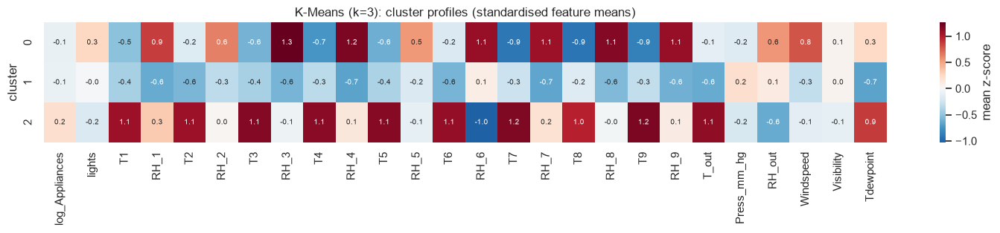

,size,median_Appliances_Wh,mean_hour,dominant_month,share_%,month_1_%,month_2_%,month_3_%,month_4_%,month_5_%
cluster,,,,,,,,,,
0,4629,60.000,10.901,2,23.456,45.000,49.000,4.000,2.000,0.000
1,9336,60.000,11.213,3,47.307,9.000,20.000,42.000,25.000,4.000
2,5770,70.000,12.453,5,29.237,0.000,0.000,7.000,32.000,61.000


In [27]:
def profile_clusters(labels, method, row_index=None):
    """Heatmap of standardised feature means and a context table for each cluster."""
    labels = pd.Series(np.asarray(labels), name="cluster")
    idx = np.arange(len(X)) if row_index is None else np.asarray(row_index)
    feature_means = X_df.iloc[idx].reset_index(drop=True).groupby(labels).mean()

    fig, ax = plt.subplots(figsize=(15, 0.6 * len(feature_means) + 1.5))
    sns.heatmap(feature_means, cmap="RdBu_r", center=0, annot=True, fmt=".1f",
                annot_kws={"size": 7}, cbar_kws={"label": "mean z-score"}, ax=ax)
    ax.set_title(f"{method}: cluster profiles (standardised feature means)")
    plt.tight_layout()
    plt.show()

    context = meta.iloc[idx].reset_index(drop=True).assign(cluster=labels.values)
    table = context.groupby("cluster").agg(size=("hour", "size"),
                                           median_Appliances_Wh=("Appliances", "median"),
                                           mean_hour=("hour", "mean"),
                                           dominant_month=("month", lambda m: m.mode()[0]))
    table["share_%"] = 100 * table["size"] / table["size"].sum()
    month_mix = pd.crosstab(context["cluster"], context["month"], normalize="index").mul(100).round(0)
    month_mix.columns = [f"month_{m}_%" for m in month_mix.columns]
    display(table.join(month_mix))

profile_clusters(kmeans_labels, f"K-Means (k={K_CHOSEN})")

**Interpretation of the K-Means clusters.** The partition is very stable: ARI > 0.99 across seeds and subsamples. It maps almost perfectly onto **climate regimes of the season**:

| Cluster | Months | Profile | Reading |
|---|---|---|---|
| 0 (23%) | 94% Jan–Feb | Indoor humidity well above average ($z≈+1$), humid and windy outside ($\bar{T}_{out}≈7$ °C, RH ≈ 88%), cooler rooms | **Mild, wet, windy winter** |
| 1 (47%) | mostly Mar, some Feb and Apr | Cold outside ($\bar{T}_{out}≈4$ °C), dry indoor air, low dew point | **Cold, dry late-winter spell** |
| 2 (29%) | 93% Apr–May | All temperatures about 1 SD above average ($\bar{T}_{out}≈13$ °C), dry outdoor air, `RH_6` far below average | **Warm spring** |

**Critical note: the clusters are not about consumption.**

- **Consumption barely differs.** The median `Appliances` is 60–70 Wh in every cluster, and the standardised means differ by only ≈0.3 SD.
- **What the algorithm actually found.** It segmented the **dominant variance directions**, temperature (PC1) and humidity (PC2), which are driven by the calendar. Behaviour was not a factor.
- **The warm cluster absorbs a sensor artifact.** Its low `RH_6` partly reflects the sensor floor found in the EDA, which occurs almost only in April–May.

**Evaluation of the metric.**

- **$W/T$ of 0.58.** The clusters remove only 42% of the variance, so they are far from compact.
- **Silhouette of 0.25.** It confirms that neighbouring clusters overlap.

These metrics correctly describe a *continuum cut into three segments* rather than well-separated groups.

### 4.3 Hierarchical (agglomerative) clustering

**Intuition.** Agglomerative clustering builds a tree of merges bottom-up: every point starts as its own cluster, and the two closest clusters are merged repeatedly. The **linkage** defines "closest":

- **Single:** minimum pairwise distance. It detects chains and is prone to the chaining effect.
- **Complete:** maximum pairwise distance. It produces compact clusters but is sensitive to outliers.
- **Average:** mean pairwise distance.
- **Ward:** the merge that least increases the within-cluster sum of squares. This is the same objective as k-means, applied greedily.

The resulting **dendrogram** shows structure at every scale, and cutting it at a chosen height gives a flat partition.

**Assumptions.** These depend on the linkage: Ward assumes compact, variance-defined clusters like k-means does, while single linkage follows connectivity.

**Strengths.** No $k$ is needed in advance, and the dendrogram is interpretable at multiple resolutions.

**Weaknesses.** Merges are greedy and irreversible. The method needs $O(n^2)$ memory and at least $O(n^2)$ time, which is why it is run on a random subsample of 5,000 observations; 19,735 points would require a ~1.5 GB distance matrix.

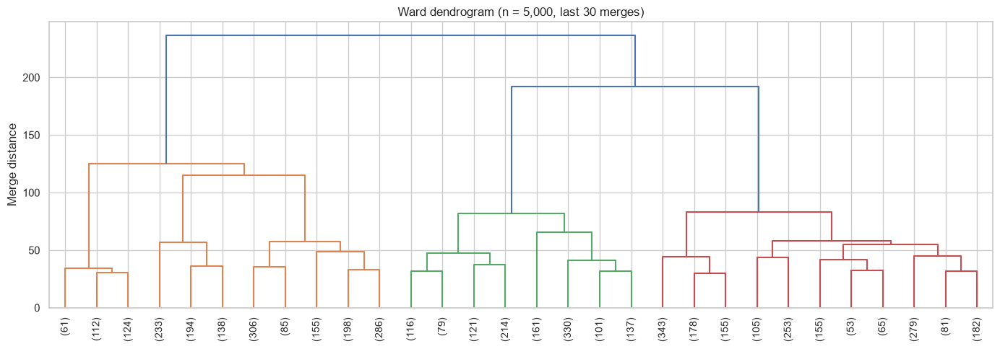

In [28]:
HC_SAMPLE = 5000
idx_hc = np.sort(rng.choice(len(Z), size=HC_SAMPLE, replace=False))
Z_hc = Z[idx_hc]
ward_tree = linkage(Z_hc, method="ward")

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(ward_tree, truncate_mode="lastp", p=30, show_leaf_counts=True,
           leaf_rotation=90, color_threshold=ward_tree[-(K_CHOSEN - 1), 2], ax=ax)
ax.set_title(f"Ward dendrogram (n = {HC_SAMPLE:,}, last 30 merges)")
ax.set_ylabel("Merge distance")
plt.tight_layout()
plt.show()

**Effect of the linkage criterion.** The tree is cut into the same number of clusters under each linkage, which isolates how much the partition depends on this single choice.

In [29]:
linkage_results = []
hc_labels_by_linkage = {}
for method in ["ward", "complete", "average", "single"]:
    tree = ward_tree if method == "ward" else linkage(Z_hc, method=method)
    labels = fcluster(tree, t=K_CHOSEN, criterion="maxclust") - 1
    hc_labels_by_linkage[method] = labels
    report = cluster_report(Z_hc, labels, f"Hierarchical ({method})")
    report["cluster sizes"] = np.bincount(labels).tolist()
    linkage_results.append(report)
display(pd.DataFrame(linkage_results).set_index("method"))

hc_labels = hc_labels_by_linkage["ward"]
print(f"ARI(Ward, K-Means) on the same {HC_SAMPLE:,} points: "
      f"{adjusted_rand_score(hc_labels, kmeans_labels[idx_hc]):.3f}")

,n_clusters,noise_%,largest_cluster_%,mean within/global var,weighted within/global var (W/T),silhouette,davies_bouldin,calinski_harabasz,cluster sizes
method,,,,,,,,,
Hierarchical (ward),3,0.000,37.840,0.608,0.612,0.211,1.423,1583.188,"[1892, 1259, 1849]"
Hierarchical (complete),3,0.000,53.180,0.609,0.658,0.155,1.450,1296.694,"[2659, 926, 1415]"
Hierarchical (average),3,0.000,76.820,0.503,0.753,0.246,1.087,819.177,"[1158, 3841, 1]"
Hierarchical (single),3,0.000,99.960,0.333,0.999,0.229,0.528,3.394,"[4998, 1, 1]"


ARI(Ward, K-Means) on the same 5,000 points: 0.609


To obtain labels for the full dataset, each Ward cluster is represented by its centroid, and every remaining observation is assigned to the nearest centroid. The profiles are then computed on all data.

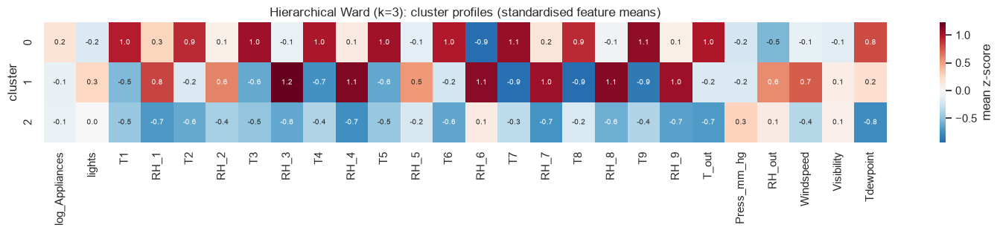

,size,median_Appliances_Wh,mean_hour,dominant_month,share_%,month_1_%,month_2_%,month_3_%,month_4_%,month_5_%
cluster,,,,,,,,,,
0,6652,70.000,12.178,5,33.707,0.000,0.000,11.000,36.000,54.000
1,4785,60.000,11.007,2,24.246,44.000,50.000,4.000,1.000,0.000
2,8298,60.000,11.245,3,42.047,10.000,21.000,43.000,23.000,4.000


In [30]:
hc_full_labels = NearestCentroid().fit(Z_hc, hc_labels).predict(Z)
profile_clusters(hc_full_labels, f"Hierarchical Ward (k={K_CHOSEN})")

### 4.4 DBSCAN

**Intuition.** DBSCAN defines clusters as dense regions separated by sparse regions. It classifies points into three types:

- A **core point** has at least `min_samples` neighbours within radius $\varepsilon$.
- Clusters are the connected components of core points, together with the **border points** within reach of them.
- Everything else is labelled **noise** (label $-1$).

**Assumptions.** Clusters have a roughly uniform density that is higher than the density between clusters. A single global $\varepsilon$ suits all of them.

**Strengths.** The number of clusters is not fixed in advance, clusters can have arbitrary shape, and there is a built-in notion of outliers.

**Weaknesses.** It is very sensitive to $\varepsilon$ and struggles when densities vary. In higher dimensions distances concentrate, which makes a single radius hard to choose.

**Parameter choice.** The rule of thumb $\texttt{min\_samples} = 2d$ is used. $\varepsilon$ is read from the **k-distance plot**, which sorts each point's distance to its $k$-th nearest neighbour; a knee indicates the transition from dense regions to sparse ones.

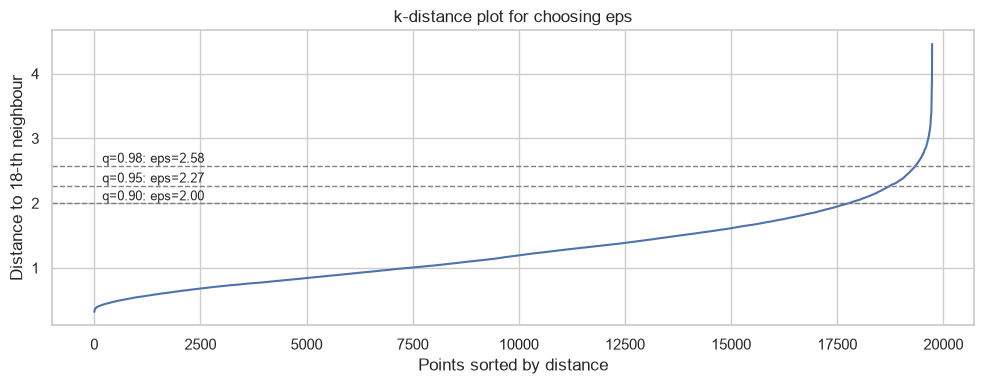

In [31]:
MIN_SAMPLES = 2 * N_PCA
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z)
k_distances = np.sort(nn.kneighbors(Z)[0][:, -1])
eps_candidates = {q: np.quantile(k_distances, q) for q in (0.90, 0.95, 0.98)}

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(k_distances)
for q, eps in eps_candidates.items():
    ax.axhline(eps, linestyle="--", linewidth=1, color="grey")
    ax.text(0, eps, f"  q={q:.2f}: eps={eps:.2f}", va="bottom", fontsize=9)
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel(f"Distance to {MIN_SAMPLES}-th neighbour")
ax.set_title("k-distance plot for choosing eps")
plt.tight_layout()
plt.show()

**Sensitivity to hyperparameters.** The grid below varies both $\varepsilon$ and `min_samples` and records the number of clusters, the share of noise and the size of the largest cluster.

In [32]:
dbscan_grid = []
for eps in [1.0, 1.5, 2.0, 2.5, 3.0, 4.0]:
    for min_samples in [MIN_SAMPLES // 2, MIN_SAMPLES, 2 * MIN_SAMPLES]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Z)
        clusters, sizes = np.unique(labels[labels != -1], return_counts=True)
        dbscan_grid.append({"eps": eps, "min_samples": min_samples, "n_clusters": len(clusters),
                            "noise_%": 100 * (labels == -1).mean(),
                            "largest_cluster_%": 100 * sizes.max() / len(labels) if len(sizes) else 0})
dbscan_grid = pd.DataFrame(dbscan_grid)
display(dbscan_grid.pivot(index="eps", columns="min_samples", values="n_clusters").add_prefix("clusters @ ms="))
display(dbscan_grid.pivot(index="eps", columns="min_samples", values="noise_%").round(1).add_prefix("noise % @ ms="))

min_samples,clusters @ ms=9,clusters @ ms=18,clusters @ ms=36
eps,,,
1.000,212,125,59
1.500,36,20,20
2.000,3,2,1
2.500,1,1,1
3.000,1,1,1
4.000,1,1,1


min_samples,noise % @ ms=9,noise % @ ms=18,noise % @ ms=36
eps,,,
1.000,28.800,45.600,73.000
1.500,5.100,14.600,27.200
2.000,0.500,2.200,6.400
2.500,0.000,0.300,0.900
3.000,0.000,0.000,0.100
4.000,0.000,0.000,0.000


**Reading the grid.** DBSCAN has no "sweet spot":

- **Small radius** ($\varepsilon \le 1.5$). The data shatter into tens or hundreds of micro-clusters, and up to 73% of the points become noise. These micro-clusters are short runs of consecutive time stamps, the same temporal chains seen in t-SNE.
- **Transition** ($\varepsilon = 2$). Almost everything merges into one component.
- **Large radius** ($\varepsilon \ge 2.5$). Everything is a single cluster.

The abrupt transition means that there are **no low-density valleys separating dense regions**: the data form one connected, continuously varying cloud.

The model below uses $\varepsilon = 2.0$ with $\texttt{min\_samples}=18$. It lies close to the 95th-percentile knee of the k-distance plot and is the most informative setting: DBSCAN then acts as a **density-based outlier detector** rather than a clustering method.

Cluster sizes (-1 = noise): {-1: 433, 0: 19293, 1: 9}


,n_clusters,noise_%,largest_cluster_%,mean within/global var,weighted within/global var (W/T),silhouette,davies_bouldin,calinski_harabasz
method,,,,,,,,
"DBSCAN (eps=2.0, ms=18)",2,2.194,97.760,0.520,1.000,0.033,1.139,8.866


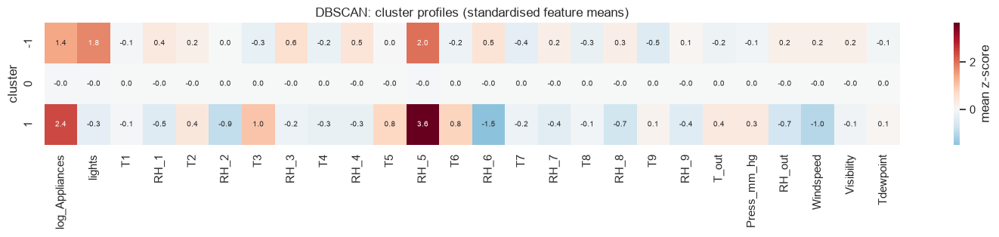

,size,median_Appliances_Wh,mean_hour,dominant_month,share_%,month_1_%,month_2_%,month_3_%,month_4_%,month_5_%
cluster,,,,,,,,,,
-1,433,180.000,16.769,1,2.194,41.000,28.000,13.000,4.000,15.000
0,19293,60.000,11.384,3,97.760,14.000,21.000,23.000,22.000,20.000
1,9,350.000,11.889,4,0.046,0.000,0.000,0.000,100.000,0.000


In [33]:
DBSCAN_EPS = 2.0
dbscan_labels = DBSCAN(eps=DBSCAN_EPS, min_samples=MIN_SAMPLES).fit_predict(Z)
print("Cluster sizes (-1 = noise):", pd.Series(dbscan_labels).value_counts().sort_index().to_dict())
display(pd.DataFrame([cluster_report(Z, dbscan_labels, f"DBSCAN (eps={DBSCAN_EPS}, ms={MIN_SAMPLES})")]).set_index("method"))
profile_clusters(dbscan_labels, "DBSCAN")

### 4.5 Comparing the three methods on the PCA projection

The three partitions are shown side by side in the same PC1–PC2 plane. DBSCAN noise is drawn in black. Metrics and pairwise agreement (ARI) are summarised below the plot.

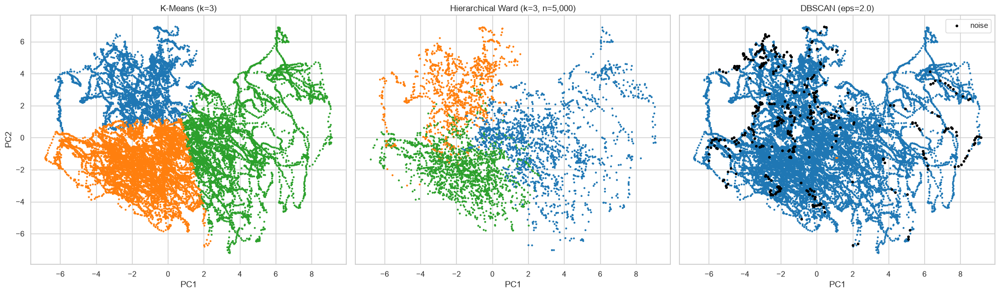

,n_clusters,noise_%,largest_cluster_%,mean within/global var,weighted within/global var (W/T),silhouette,davies_bouldin,calinski_harabasz
method,,,,,,,,
K-Means,3,0.000,47.307,0.591,0.577,0.251,1.347,7219.647
"Hierarchical Ward (full, nearest centroid)",3,0.000,42.047,0.586,0.581,0.245,1.342,7112.860
DBSCAN,2,2.194,97.760,0.520,1.000,0.033,1.139,8.866


Pairwise Adjusted Rand Index:


,K-Means,Ward,DBSCAN
K-Means,1.000,0.824,0.005
Ward,0.824,1.000,0.004
DBSCAN,0.005,0.004,1.000


In [34]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)
panels = [(kmeans_labels, np.arange(len(Z)), f"K-Means (k={K_CHOSEN})"),
          (hc_labels, idx_hc, f"Hierarchical Ward (k={K_CHOSEN}, n={HC_SAMPLE:,})"),
          (dbscan_labels, np.arange(len(Z)), f"DBSCAN (eps={DBSCAN_EPS})")]
for ax, (labels, idx, title) in zip(axes, panels):
    noise = labels == -1
    ax.scatter(Z_all[idx[~noise], 0], Z_all[idx[~noise], 1], s=3,
               c=labels[~noise], cmap="tab10", vmin=0, vmax=9)
    if noise.any():
        ax.scatter(Z_all[idx[noise], 0], Z_all[idx[noise], 1], s=8, c="black", label="noise")
        ax.legend(loc="upper right")
    ax.set_title(title)
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.tight_layout()
plt.show()

comparison = pd.DataFrame([cluster_report(Z, kmeans_labels, "K-Means"),
                           cluster_report(Z, hc_full_labels, "Hierarchical Ward (full, nearest centroid)"),
                           cluster_report(Z, dbscan_labels, "DBSCAN")]).set_index("method")
display(comparison)
ari = pd.DataFrame({a: [adjusted_rand_score(la, lb) for lb in (kmeans_labels, hc_full_labels, dbscan_labels)]
                    for a, la in [("K-Means", kmeans_labels), ("Ward", hc_full_labels), ("DBSCAN", dbscan_labels)]},
                   index=["K-Means", "Ward", "DBSCAN"])
print("Pairwise Adjusted Rand Index:")
display(ari)

### 4.5.1 Discussion of the sample clustering

**Hierarchical clustering.**

- **Agreement with K-Means.** Ward linkage reproduces the three seasonal regimes, with ARI 0.82 against K-Means on the full data. Both minimise within-cluster variance, one greedily and one iteratively, so they converge to similar partitions.
- **Sensitivity to the linkage.** Changing only the linkage changes the result drastically:
  - **Average linkage:** one dominant cluster plus a singleton.
  - **Single linkage:** one cluster containing 99.9% of the points plus isolated points. This is the chaining effect.

- **Dendrogram.** There is a visible height gap above the three-cluster level, which supports $k=3$. However, Ward merge costs grow with cluster size by construction, so tall upper branches alone are weak evidence of natural groups; the low silhouette remains the more reliable signal.

**DBSCAN** finds one dominant cluster (98%), a 9-point micro-cluster (high-consumption readings from April, median 350 Wh) and 2.2% noise. The noise points are informative:

- their median consumption is **180 Wh**, three times the typical 60 Wh;
- they concentrate in the late afternoon and evening.

DBSCAN has isolated **high-activity periods**, not a new climate regime.

**Why the algorithms disagree.** The ARI between DBSCAN and the other two methods is ≈0, because they answer different questions:

- **Centroid-based methods (K-Means, Ward)** must partition *every* point into $k$ convex groups. On a continuous cloud they cut along the direction of largest spread (here the seasonal temperature axis) whether or not a natural boundary exists.
- **Density-based methods (DBSCAN)** only report groups separated by low-density gaps. Finding none, they return one cluster plus low-density outliers.

**Cluster geometry.** The data form an elongated, curved manifold that follows the seasonal trajectory, with thin temporal "strands" along it. This geometry violates K-Means' assumption of spherical clusters and DBSCAN's assumption of density valleys.

**Sensitivity to hyperparameters.** The three methods differ strongly:

- **K-Means:** stable for a fixed $k$, but $k$ itself is weakly identified, since silhouette is nearly flat for $k=2$–4.
- **Hierarchical clustering:** extremely sensitive to the linkage.
- **DBSCAN:** extremely sensitive to $\varepsilon$, jumping from over 100 clusters to 1 within one unit of distance.

**When clustering fails, as here.**

- **No discrete groups.** The data vary continuously, driven by a slowly drifting season.
- **Dependent samples.** Rows are temporally autocorrelated, not independent.
- **Dominance of variance.** The dominant variance directions are not the ones of practical interest.

**Conclusion.** The honest conclusion is that **this dataset contains no strong natural cluster structure**. The most defensible partition is a coarse seasonal segmentation. That result is still useful, for example as context for anomaly detection, but it is a discretisation of a continuum rather than a discovery of distinct household "types".

### 4.6 Clustering the feature space (transpose of the data matrix)

The same tools can be applied to the **columns** instead of the rows. Each of the 26 features is then a point in $\mathbb{R}^{n}$, one coordinate per time stamp. For standardised columns, the squared Euclidean distance between features $a$ and $b$ is determined entirely by their correlation:

$$
\lVert x_a - x_b\rVert^2 = 2n\,(1 - r_{ab}).
$$

Two approaches are compared:

1. **Hierarchical clustering with distance $d_{ab} = 1 - |r_{ab}|$** (average linkage). This treats strongly *anti*-correlated features as redundant too, because one is essentially the mirror image of the other.
2. **K-Means on $X^\top$.** This is equivalent to clustering on the *signed* correlation, so anti-correlated features are pushed apart.

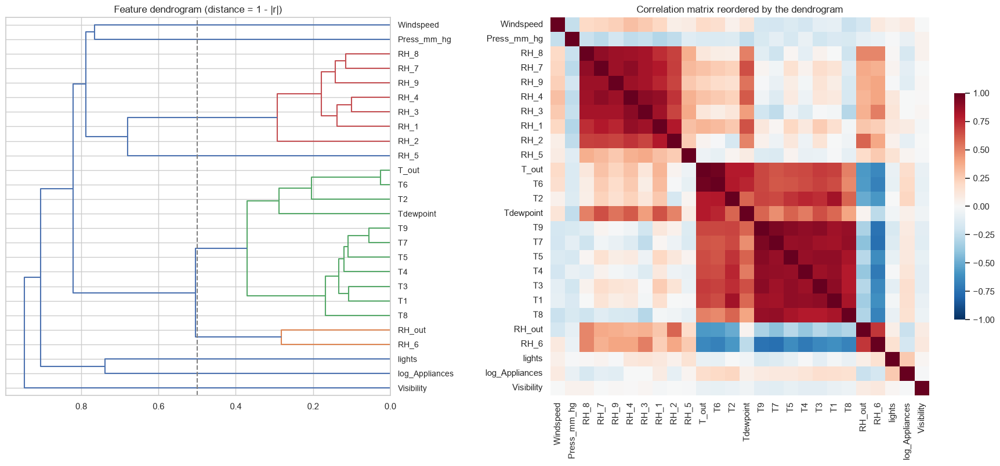

hierarchical (1-|r|):
   group 1: log_Appliances
   group 2: lights
   group 3: RH_6, RH_out
   group 4: T1, T2, T3, T4, T5, T6, T7, T8, T9, T_out, Tdewpoint
   group 5: RH_1, RH_2, RH_3, RH_4, RH_7, RH_8, RH_9
   group 6: RH_5
   group 7: Press_mm_hg
   group 8: Windspeed
   group 9: Visibility
k-means on X^T (signed r):
   group 1: T1, T3, T4, T5, T7, T8, T9
   group 2: RH_5
   group 3: log_Appliances, lights
   group 4: RH_1, RH_2, RH_3, RH_4, RH_7, RH_8, RH_9
   group 5: Visibility
   group 6: Press_mm_hg
   group 7: RH_6, RH_out
   group 8: T2, T6, T_out, Tdewpoint
   group 9: Windspeed

ARI between the two feature partitions: 0.719


In [35]:
feature_corr = X_df.corr()
feature_dist = 1 - feature_corr.abs()
feature_tree = linkage(squareform(feature_dist.values, checks=False), method="average")

FEATURE_CUT = 0.5    # merge groups whose average |r| exceeds 0.5
feature_groups_hc = fcluster(feature_tree, t=FEATURE_CUT, criterion="distance")
n_feature_groups = len(np.unique(feature_groups_hc))

fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1, 1.3]})
dendro = dendrogram(feature_tree, labels=FEATURES, orientation="left",
                    color_threshold=FEATURE_CUT, ax=axes[0])
axes[0].axvline(FEATURE_CUT, color="grey", linestyle="--")
axes[0].set_title("Feature dendrogram (distance = 1 - |r|)")
order = dendro["ivl"][::-1]
sns.heatmap(feature_corr.loc[order, order], cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.6}, ax=axes[1])
axes[1].set_title("Correlation matrix reordered by the dendrogram")
plt.tight_layout()
plt.show()

km_features = KMeans(n_clusters=n_feature_groups, n_init=20, random_state=RANDOM_STATE).fit(X.T)
feature_clusters = pd.DataFrame({"hierarchical (1-|r|)": feature_groups_hc,
                                 "k-means on X^T (signed r)": km_features.labels_ + 1},
                                index=FEATURES)
for col in feature_clusters:
    print(f"{col}:")
    for g, members in feature_clusters.groupby(col).groups.items():
        print(f"   group {g}: {', '.join(members)}")
print(f"\nARI between the two feature partitions: "
      f"{adjusted_rand_score(feature_clusters.iloc[:, 0], feature_clusters.iloc[:, 1]):.3f}")

**What feature clustering reveals.**

**Redundant groups.** Both partitions (ARI 0.72) recover the same physical blocks:

- **Temperatures:** all indoor rooms together with the outdoor and station temperatures and the dew point.
- **Indoor humidities:** seven rooms.
- **Outdoor humidity:** `RH_6` with `RH_out`.
- **Energy:** `log_Appliances` with `lights`, in the k-means partition.

Within a block, one or two representatives would carry most of the information. This is a data-driven route to **feature selection**, consistent with the participation ratio of ≈5 found by PCA.

**Isolated features.** Several features belong to no group:

- **`RH_5` (bathroom humidity):** driven by showers, not by the building's climate.
- **Pressure, wind speed and visibility:** independent weather variables.
- **Energy features:** `log_Appliances` and `lights` form singletons (hierarchical) or a small separate pair (k-means). Consumption is statistically *decoupled* from the climate sensors.

**Signed versus absolute correlation.** The two distances disagree in instructive ways:

- **K-Means on $X^\top$ (signed correlation)** separates `T2`, `T6`, `T_out` and `Tdewpoint` from the other room temperatures. The living room (`T2`) tracks outdoor conditions more closely than the other rooms, plausibly because of solar gains through its windows.
- **Hierarchical clustering on $1-|r|$** merges all temperatures, because the within-block correlations are all high.

The choice of distance therefore encodes a modelling assumption, namely whether *anti*-correlation counts as similarity.

**Insight not visible from sample clustering.** Sample clustering showed three seasonal regimes. Feature clustering explains *why*: roughly 20 of the 26 features are two blocks of near-duplicate climate sensors. They dominate every Euclidean distance, so any sample-level method is effectively clustering on temperature and humidity.

**Where feature clustering is especially useful.** It pays off wherever many features measure the same underlying factor:

- **Genomics:** co-expressed gene modules.
- **Finance:** correlated assets and sector structure.
- **Sensor networks and IoT:** redundant sensors, and detecting a failing sensor that drifts away from its group.
- **Text:** co-occurring terms.
- **Preprocessing** for any high-dimensional model, to reduce multicollinearity.

## 5. Multi-Dimensional Anomaly Detection

All detectors run on the **full standardised 26-dimensional matrix** $X$, rather than the PCA projection. Low-variance directions discarded by PCA are exactly where some anomalies live: a point can be ordinary in each feature separately but violate the usual *relationship* between features.

**Common flagging budget.** Each method produces a continuous anomaly score, oriented so that higher means more anomalous. There is no ground truth, so each method flags the **top 1% of observations** (≈197 rows). This makes the methods directly comparable. The 1% budget is a pragmatic choice rather than a property of the data, and its effect is analysed in Section 5.2.

In [36]:
CONTAMINATION = 0.01
N_FLAG = int(round(CONTAMINATION * len(X)))

def top_flags(scores, n=N_FLAG):
    """Boolean mask marking the n highest anomaly scores."""
    flags = np.zeros(len(scores), dtype=bool)
    flags[np.argsort(scores)[-n:]] = True
    return flags

def jaccard(a, b):
    """Overlap of two boolean flag vectors: |A and B| / |A or B|."""
    return (a & b).sum() / max((a | b).sum(), 1)

def plot_anomalies_on_pca(flag_sets, title):
    """Scatter PC1-PC2 with flagged observations highlighted, one panel per method."""
    fig, axes = plt.subplots(1, len(flag_sets), figsize=(7 * len(flag_sets), 5.5), sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (name, flags) in zip(axes, flag_sets.items()):
        ax.scatter(Z_all[~flags, 0], Z_all[~flags, 1], s=2, c="lightgrey", label="normal")
        ax.scatter(Z_all[flags, 0], Z_all[flags, 1], s=12, c="crimson", label=f"anomaly (n={flags.sum()})")
        ax.set_title(name)
        ax.set_xlabel("PC1")
        ax.legend(loc="upper right", markerscale=2)
    axes[0].set_ylabel("PC2")
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()

print(f"Flagging budget: top {CONTAMINATION:.0%} = {N_FLAG} observations per method")

Flagging budget: top 1% = 197 observations per method


### 5.1 Z-score method

**Feature-wise (univariate).** For each feature, $z_{ij} = (x_{ij} - \mu_j)/\sigma_j$. A classical rule flags an observation if $|z_{ij}| > 3$ for **any** feature $j$. Under a Gaussian, $P(|z|>3) \approx 0.27\%$ per feature.

**Why it degrades in high dimensions.** Suppose the $d$ features were independent Gaussians. Then the probability that *at least one* of them exceeds the threshold is $1-(1-0.0027)^d$. For $d=26$ that is already ≈6.8% of perfectly normal data. The rule therefore turns into a multiple-testing problem, and its false-alarm rate grows with $d$.

**Why it can miss anomalies.** The rule examines each axis separately, so it cannot see a *combination* that is unusual. An example would be a warm bathroom with low humidity, where each value alone is ordinary.

The cell below compares the observed flag rates with this Gaussian expectation.

Rows with at least one |z| > 3 : 10.98% (2,166 rows)
Expected if Gaussian & independent: 6.79%


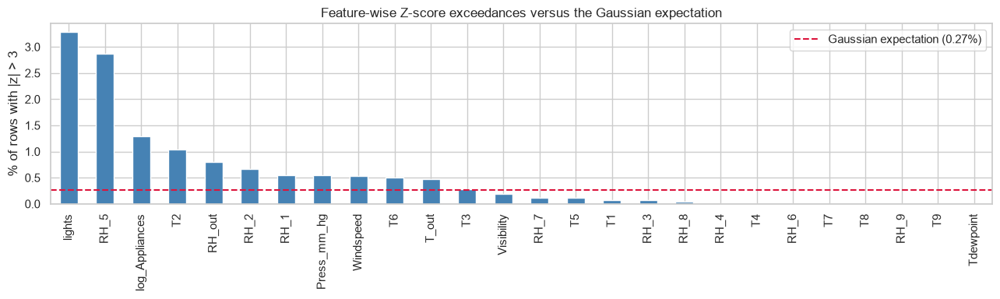

In [37]:
abs_z = X_df.abs()
p_gauss = 2 * stats.norm.sf(3)
flag_any = (abs_z > 3).any(axis=1)

print(f"Rows with at least one |z| > 3 : {flag_any.mean():.2%} ({flag_any.sum():,} rows)")
print(f"Expected if Gaussian & independent: {1 - (1 - p_gauss) ** X.shape[1]:.2%}")

per_feature = (abs_z > 3).mean().mul(100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(13, 4))
per_feature.plot.bar(ax=ax, color="steelblue")
ax.axhline(100 * p_gauss, color="crimson", linestyle="--", label=f"Gaussian expectation ({p_gauss:.2%})")
ax.set_ylabel("% of rows with |z| > 3")
ax.set_title("Feature-wise Z-score exceedances versus the Gaussian expectation")
ax.legend()
plt.tight_layout()
plt.show()

**Global (multivariate) version: Mahalanobis distance.** The natural multivariate generalisation of the z-score is

$$
D^2(x) = (x-\mu)^\top \Sigma^{-1} (x-\mu),
$$

which measures distance in units of the data's own covariance, so correlated directions are not double-counted.

- **If $x$ is Gaussian:** $D^2 \sim \chi^2_d$, which gives a principled threshold.
- **Q–Q plot against $\chi^2_{26}$:** this tests the Gaussian assumption on the joint distribution.

For the comparison in Section 6, two scores are used:

- **Feature-wise z-score:** the maximum absolute z-score across features, $\max_j |z_{ij}|$.
- **Global method:** the Mahalanobis distance $D^2$.

chi2(26) 99% threshold = 45.6; rows above it: 6.71% (expected 1.00% if Gaussian)


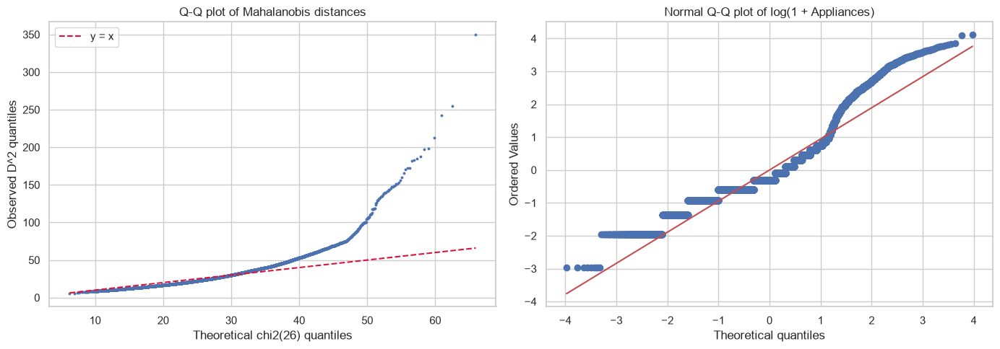

Jaccard(feature-wise z-score, Mahalanobis) = 0.05


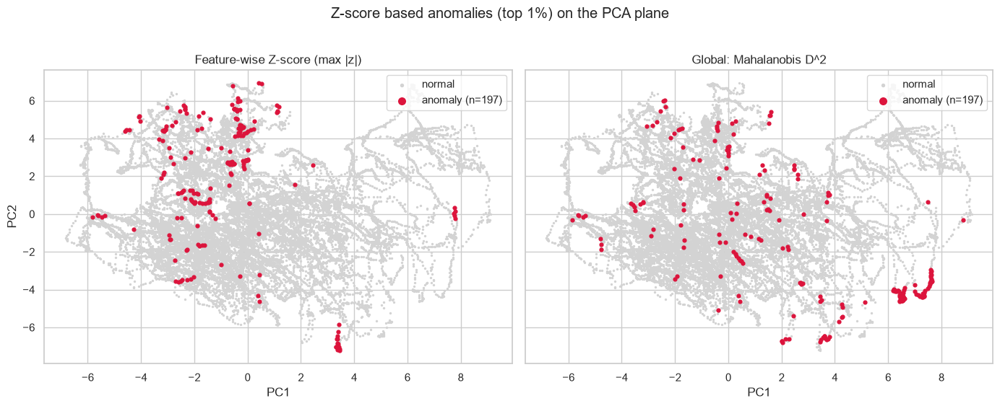

In [38]:
z_scores = abs_z.max(axis=1).to_numpy()
mahalanobis_sq = EmpiricalCovariance().fit(X).mahalanobis(X)
chi2_threshold = stats.chi2.ppf(0.99, df=X.shape[1])

print(f"chi2(26) 99% threshold = {chi2_threshold:.1f}; rows above it: "
      f"{(mahalanobis_sq > chi2_threshold).mean():.2%} (expected 1.00% if Gaussian)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
theoretical = stats.chi2.ppf((np.arange(1, len(X) + 1) - 0.5) / len(X), df=X.shape[1])
axes[0].scatter(theoretical, np.sort(mahalanobis_sq), s=3)
axes[0].plot(theoretical, theoretical, color="crimson", linestyle="--", label="y = x")
axes[0].set_xlabel("Theoretical chi2(26) quantiles")
axes[0].set_ylabel("Observed D^2 quantiles")
axes[0].set_title("Q-Q plot of Mahalanobis distances")
axes[0].legend()
stats.probplot(X_df["log_Appliances"], dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot of log(1 + Appliances)")
plt.tight_layout()
plt.show()

zscore_flags = top_flags(z_scores)
mahalanobis_flags = top_flags(mahalanobis_sq)
print(f"Jaccard(feature-wise z-score, Mahalanobis) = {jaccard(zscore_flags, mahalanobis_flags):.2f}")
plot_anomalies_on_pca({"Feature-wise Z-score (max |z|)": zscore_flags,
                       "Global: Mahalanobis D^2": mahalanobis_flags},
                      "Z-score based anomalies (top 1%) on the PCA plane")

**Findings.**

**The Gaussian assumption fails, both marginally and jointly.**

- **Feature-wise.** 11.0% of rows exceed $|z|>3$ on at least one feature, against 6.8% expected under independent Gaussians. The excess comes from the heavy-tailed variables: `lights`, `RH_5`, `log_Appliances`, `Visibility` and `T2` exceed the 0.27% Gaussian rate many times over.
- **Globally.** 6.7% of rows exceed the $\chi^2_{26}$ 99% threshold instead of 1%, and the Q–Q plot curves away from the diagonal in the upper tail. A $\chi^2$-based threshold would flag six times too many observations.

**Feature-wise and global versions disagree almost completely** (Jaccard 0.05):

- **Feature-wise method.** It catches the *magnitude* of single variables: evening showers (`RH_5`) and lights switched on (`lights`).
- **Mahalanobis.** It catches *broken correlations*: observations whose combination of values is inconsistent with the usual covariance. Examples are a humid kitchen during a dry spell, or the outdoor sensor reading 1% humidity while the weather station reports 50%.

Neither is "right". They define anomalies differently.

**High dimensions and covariance.**

- **Multiple testing.** The feature-wise rule's false-alarm rate grows with $d$.
- **Unstable covariance.** Mahalanobis requires inverting $\Sigma$. With a condition number of ≈2,500, the inverse amplifies noise in near-degenerate directions, so tiny deviations in those directions receive huge distances.
- **Masking.** The covariance is estimated *including* the anomalies, so extreme points inflate $\Sigma$ and hide themselves. A robust estimator such as the Minimum Covariance Determinant would reduce this effect.

### 5.2 Isolation Forest

**Isolation mechanism.** Anomalies are *few and different*, so they are easier to separate from the rest than normal points are. Each isolation tree is built by:

- drawing a random subsample of 256 rows;
- repeatedly picking a **random feature** and a **random split value** uniformly between that feature's minimum and maximum in the current node;
- stopping when a point is isolated.

**Role of random partitioning.** Points in sparse regions are cut off after few random splits, while points deep inside dense regions need many. The path length $h(x)$ is therefore a proxy for local sparsity. Averaging over many random trees removes the dependence on any single random partition.

**Anomaly score.** With $c(m)$ the average path length of an unsuccessful binary-search-tree search over $m$ points:

$$
s(x) = 2^{-E[h(x)]/c(m)} .
$$

- $s \to 1$: very short paths, a clear anomaly.
- $s \approx 0.5$ or below: typical point.

**Contamination.** This parameter does **not** change the model or the scores. It only sets the score threshold that separates "anomaly" from "normal" (the $(1-c)$-quantile of the scores). The code below demonstrates this by comparing several values.

In [39]:
start = time.perf_counter()
iforest = IsolationForest(n_estimators=300, contamination=CONTAMINATION,
                          random_state=RANDOM_STATE, n_jobs=-1).fit(X)
iforest_scores = -iforest.score_samples(X)          # = s(x); higher = more anomalous
print(f"Fit + score time: {time.perf_counter() - start:.2f} s")
iforest_flags = top_flags(iforest_scores)

contamination_table = pd.DataFrame([
    {"contamination": c,
     "score threshold s(x)": np.quantile(iforest_scores, 1 - c),
     "n flagged": int((iforest_scores > np.quantile(iforest_scores, 1 - c)).sum())}
    for c in (0.005, 0.01, 0.02, 0.05, 0.10)]).set_index("contamination")
display(contamination_table)
print(f"Rows with s(x) > 0.5: {(iforest_scores > 0.5).mean():.2%} | "
      f"max s(x) = {iforest_scores.max():.3f}")

seed_jaccard = [jaccard(iforest_flags,
                        top_flags(-IsolationForest(n_estimators=300, random_state=s, n_jobs=-1)
                                  .fit(X).score_samples(X)))
                for s in range(5)]
print("Jaccard of top-1% flags across 5 other seeds:", np.round(seed_jaccard, 2))

Fit + score time: 1.36 s


,score threshold s(x),n flagged
contamination,,
0.005,0.583,99
0.010,0.576,198
0.020,0.563,395
0.050,0.538,987
0.100,0.516,1974


Rows with s(x) > 0.5: 14.39% | max s(x) = 0.613
Jaccard of top-1% flags across 5 other seeds: [0.67 0.5  0.43 0.36 0.61]


**Visualisation.** The left panel shows the distribution of scores with the thresholds implied by different contamination values. The right panel shows the flagged observations on the PCA plane.

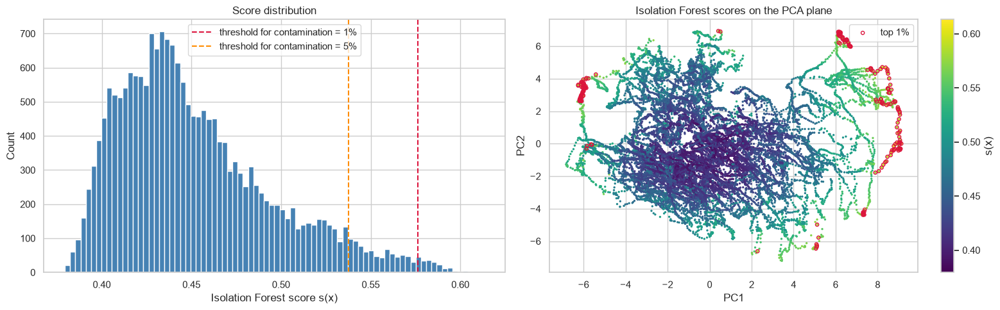

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(iforest_scores, bins=80, color="steelblue")
for c, color in [(0.01, "crimson"), (0.05, "darkorange")]:
    axes[0].axvline(np.quantile(iforest_scores, 1 - c), color=color, linestyle="--",
                    label=f"threshold for contamination = {c:.0%}")
axes[0].set_xlabel("Isolation Forest score s(x)")
axes[0].set_ylabel("Count")
axes[0].set_title("Score distribution")
axes[0].legend()

points = axes[1].scatter(Z_all[:, 0], Z_all[:, 1], c=iforest_scores, cmap="viridis", s=2)
axes[1].scatter(Z_all[iforest_flags, 0], Z_all[iforest_flags, 1], s=14,
                facecolors="none", edgecolors="crimson", label="top 1%")
fig.colorbar(points, ax=axes[1], label="s(x)")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("Isolation Forest scores on the PCA plane")
axes[1].legend()
plt.tight_layout()
plt.show()

**Findings.**

**No strongly isolated points exist.**

- **Scores are low.** The maximum score is only 0.61, and 86% of rows score below 0.5.
- **The distribution has no separate mode.** The histogram shows a continuous right tail without a distinct cluster of high-scoring points.
- **Interpretation.** In the terms of the original paper, the dataset contains no observations that are "clearly anomalous". The top 1% are simply the most isolated end of a continuum.

**Contamination only moves the threshold.** Changing it from 0.5% to 10% moves the cut-off from 0.583 to 0.516, while the scores stay the same. The choice of contamination is therefore a *decision* about the alarm budget, not something the algorithm learns. Without labels it must be justified by operational cost, meaning how many alerts can realistically be investigated.

**The top-1% set is unstable across random seeds** (Jaccard 0.36–0.67). This is a direct consequence of the weak separation:

- When many points have nearly identical scores near the threshold, the randomness of the partitions reorders them.
- Only the few highest-scoring points are reproducible.
- More trees would reduce this variance but cannot create separation that does not exist.

**Strengths.**

- **Linear cost.** Each tree uses a subsample of 256 points, so fitting is fast even for large $n$.
- **No distance computation.** Isolation relies on random splits rather than pairwise distances.
- **Scale invariance.** It is invariant to per-feature scaling, because splits are drawn uniformly within each feature's range (verified in Section 6.3).

**Limitations in high dimensions.**

- **Irrelevant features dilute it.** Splits are made on randomly chosen features, so irrelevant features waste splits. This dilution is quantified in Section 6.3.
- **Axis-parallel splits.** They struggle with anomalies defined by *correlations* between features, such as a diagonal structure.
- **Bias toward global extremes.** The method favours points at the edges of the joint range. This explains why its flags overlap with Mahalanobis (the `RH_6` artifact) more than with LOF.

### 5.3 Local Outlier Factor (LOF)

**Local density estimation.** For each point $x$ with neighbourhood $N_k(x)$, LOF computes:

- **Reachability distance** to a neighbour $o$: $\text{reach}_k(x,o)=\max\{k\text{-dist}(o), d(x,o)\}$. This smooths distances inside dense regions.
- **Local reachability density:** $\text{lrd}_k(x) = 1 / \operatorname{mean}_{o\in N_k(x)} \text{reach}_k(x,o)$.
- **Local outlier factor:**
$$
\mathrm{LOF}_k(x) = \frac{\operatorname{mean}_{o\in N_k(x)}\,\text{lrd}_k(o)}{\text{lrd}_k(x)} .
$$

$\mathrm{LOF}\approx 1$ means the point is as dense as its neighbours, and $\mathrm{LOF}\gg 1$ means it is much sparser than its neighbourhood.

**Global versus local anomalies.** Because density is compared *relative to the neighbourhood*, LOF can detect a point that sits slightly outside a tight cluster, even if a globally-scaled method such as Mahalanobis would call it ordinary. Conversely, a whole group of rare but mutually similar points can look normal to LOF, because its members are each other's neighbours. This is the **masking or neighbourhood effect**.

**Sensitivity to $k$.** A small $k$ makes LOF react to micro-structure and noise. A large $k$ smooths densities toward a global view. The analysis uses $k=20$, the value recommended in the original paper, and measures how much the flagged set changes for other values of $k$.

In [41]:
LOF_K = 20
start = time.perf_counter()
lof = LocalOutlierFactor(n_neighbors=LOF_K).fit(X)
lof_scores = -lof.negative_outlier_factor_          # = LOF_k(x); higher = more anomalous
print(f"Fit + score time: {time.perf_counter() - start:.2f} s")
lof_flags = top_flags(lof_scores)
print(f"LOF quantiles: median = {np.median(lof_scores):.2f}, 99th pct = {np.quantile(lof_scores, 0.99):.2f}, "
      f"max = {lof_scores.max():.2f}")

k_sensitivity = []
for k in (5, 10, 20, 50, 100, 200):
    scores_k = -LocalOutlierFactor(n_neighbors=k).fit(X).negative_outlier_factor_
    flags_k = top_flags(scores_k)
    k_sensitivity.append({"k": k,
                          "Jaccard vs k=20": jaccard(flags_k, lof_flags),
                          "Spearman rho of scores vs k=20": stats.spearmanr(scores_k, lof_scores)[0],
                          "overlap with Mahalanobis top 1%": jaccard(flags_k, mahalanobis_flags)})
display(pd.DataFrame(k_sensitivity).set_index("k"))

mahalanobis_percentile = stats.rankdata(mahalanobis_sq) / len(X)
print(f"LOF anomalies that are NOT in the Mahalanobis top 10% (purely local anomalies): "
      f"{(mahalanobis_percentile[lof_flags] < 0.90).mean():.0%}")

Fit + score time: 0.91 s
LOF quantiles: median = 1.04, 99th pct = 1.69, max = 2.66


,Jaccard vs k=20,Spearman rho of scores vs k=20,overlap with Mahalanobis top 1%
k,,,
5,0.088,0.267,0.000
10,0.263,0.573,0.003
20,1.000,1.000,0.010
50,0.152,0.517,0.079
100,0.101,0.331,0.126
200,0.051,0.268,0.149


LOF anomalies that are NOT in the Mahalanobis top 10% (purely local anomalies): 87%


**Visualisation.** The plot places the anomalies flagged by LOF next to those flagged by Isolation Forest on the same PCA plane, which makes the difference between local and global anomalies visible.

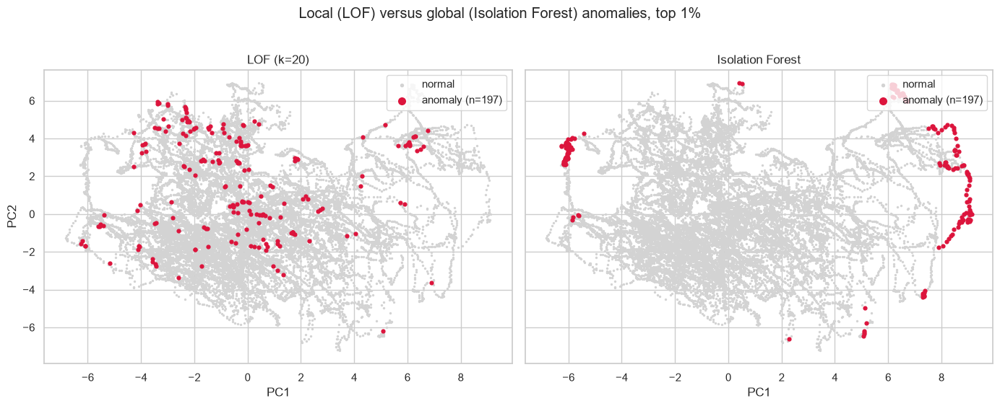

In [42]:
plot_anomalies_on_pca({f"LOF (k={LOF_K})": lof_flags, "Isolation Forest": iforest_flags},
                      "Local (LOF) versus global (Isolation Forest) anomalies, top 1%")

**Findings.**

**LOF values are modest.** The median is 1.04, the 99th percentile 1.69 and the maximum 2.66. Most points are about as dense as their neighbours, and even the strongest local outliers are less than three times sparser than their neighbourhood.

**LOF is highly sensitive to $k$.** The top-1% set at $k=20$ shares only 9–26% of its members with $k=5$ or $k=10$, and 5–15% with $k \ge 50$. The reason is the 10-minute sampling:

- **Small $k$.** A point's nearest neighbours are its own temporal predecessors and successors, so LOF measures *how smoothly the series evolves*. A sudden jump between consecutive readings is what gets flagged.
- **Large $k$.** Neighbourhoods span several days, and LOF drifts toward a global notion of outlyingness. Its overlap with Mahalanobis rises from 0% to 15%.

**LOF finds local anomalies.**

- **They are not global outliers.** 87% of the LOF anomalies are **not** in the global Mahalanobis top 10%, and 96% lie inside the bulk of the PCA plane.
- **Different drivers.** They are dominated by the weather variables `Visibility` and `Windspeed`, whose interpolated, step-like series create points that sit oddly relative to their temporal neighbours.
- **Blind spot.** LOF ignores the `RH_6` sensor floor almost completely: only 1% of its anomalies, below the 7.4% base rate. The floor affects over 1,400 rows, so those rows form a *dense* group, and a dense group of anomalies masks itself under a local-density criterion. This is the **neighbourhood (masking) effect** in practice.

## 6. Comparison of the Anomaly Detection Methods

### 6.1 Agreement between methods

The comparison uses two complementary views, since the same top-1% budget makes the flag sets directly comparable:

- **Jaccard overlap of the flagged sets:** do the methods agree on *which* rows are anomalies?
- **Spearman correlation of the full score vectors:** do they agree on the *ranking* of all rows?

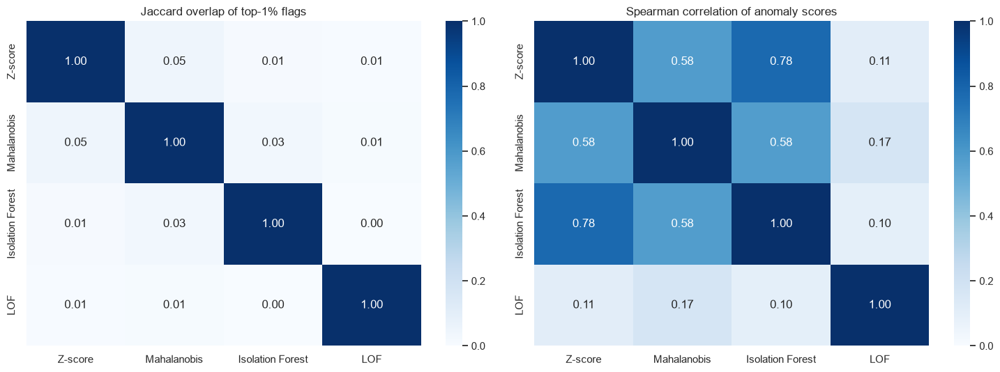

Number of methods flagging each row (rows flagged by at least one method):


,n_rows
1,716
2,30
3,4


,n_rows
LOF,192
Isolation Forest,180
Z-score,177
Mahalanobis,167
Z-score + Mahalanobis,13
Mahalanobis + Isolation Forest,11
Z-score + Isolation Forest,3
Z-score + Mahalanobis + Isolation Forest,2
Z-score + Mahalanobis + LOF,2
Mahalanobis + LOF,2


In [43]:
METHODS = ["Z-score", "Mahalanobis", "Isolation Forest", "LOF"]
scores = pd.DataFrame({"Z-score": z_scores, "Mahalanobis": mahalanobis_sq,
                       "Isolation Forest": iforest_scores, "LOF": lof_scores})
flags = pd.DataFrame({"Z-score": zscore_flags, "Mahalanobis": mahalanobis_flags,
                      "Isolation Forest": iforest_flags, "LOF": lof_flags})

jaccard_matrix = pd.DataFrame([[jaccard(flags[a], flags[b]) for b in METHODS] for a in METHODS],
                              index=METHODS, columns=METHODS)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(jaccard_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Jaccard overlap of top-1% flags")
sns.heatmap(scores.corr(method="spearman"), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Spearman correlation of anomaly scores")
plt.tight_layout()
plt.show()

n_methods = flags.sum(axis=1)
print("Number of methods flagging each row (rows flagged by at least one method):")
display(n_methods[n_methods > 0].value_counts().sort_index().rename("n_rows").to_frame())
combos = flags[n_methods > 0].apply(lambda r: " + ".join(m for m in METHODS if r[m]), axis=1)
display(combos.value_counts().rename("n_rows").to_frame())

### 6.2 Consensus anomalies and method-specific anomalies

For each flagged row, the **three features with the largest $|z|$** serve as a simple explanation of *why* it is unusual. The time of day and the raw consumption place it in its real-world context. The first table shows the consensus anomalies (flagged by at least three methods), and the second shows how many anomalies each method finds *alone*, together with their dominant features.

In [44]:
def explain_rows(row_index, n_features=3):
    """Context and the most deviating features (largest |z|) for the given rows."""
    table = meta.loc[row_index, ["date", "hour", "Appliances"]].copy()
    table["n_methods"] = n_methods.loc[row_index]
    table["IF score"] = scores.loc[row_index, "Isolation Forest"].round(3)
    table["LOF"] = scores.loc[row_index, "LOF"].round(2)
    table["top deviating features (z)"] = [
        ", ".join(f"{f} ({X_df.loc[i, f]:+.1f})" for f in X_df.loc[i].abs().nlargest(n_features).index)
        for i in row_index]
    return table

consensus_idx = n_methods[n_methods >= 3].index
print(f"Consensus anomalies (>= 3 of 4 methods): {len(consensus_idx)}")
display(explain_rows(consensus_idx).sort_values(["n_methods", "IF score"], ascending=False).head(15))

print("Method-specific anomalies (flagged by exactly one method):")
for method in METHODS:
    only = flags.index[flags[method] & (n_methods == 1)]
    driver_counts = pd.Series([X_df.loc[i].abs().idxmax() for i in only]).value_counts().head(4)
    print(f"  {method:<17}: {len(only):4d} rows | most common dominant feature: "
          + ", ".join(f"{f} ({c})" for f, c in driver_counts.items()))

rh6_floor = (df["RH_6"] == 1.0).to_numpy()
print(f"\nKnown artifact check - share of rows with RH_6 stuck at 1.0% (base rate {rh6_floor.mean():.1%}):")
print({m: f"{rh6_floor[flags[m]].mean():.1%}" for m in METHODS})

Consensus anomalies (>= 3 of 4 methods): 4


,date,hour,Appliances,n_methods,IF score,LOF,top deviating features (z)
1312,2016-01-20 19:40:00,19,360,3,0.582,1.180,"lights (+4.6), log_Appliances (+2.4), T4 (-2.3)"
1313,2016-01-20 19:50:00,19,330,3,0.582,1.310,"lights (+5.8), T4 (-2.3), log_Appliances (+2.3)"
2185,2016-01-26 21:10:00,21,50,3,0.482,2.150,"RH_1 (+4.3), RH_2 (+2.3), T8 (-2.1)"
3468,2016-02-04 19:00:00,19,100,3,0.449,1.750,"RH_1 (+4.4), RH_4 (+2.1), RH_3 (+1.6)"


Method-specific anomalies (flagged by exactly one method):
  Z-score          :  177 rows | most common dominant feature: RH_5 (82), lights (76), RH_2 (14), T2 (5)
  Mahalanobis      :  167 rows | most common dominant feature: RH_1 (41), RH_out (40), RH_2 (22), RH_5 (18)
  Isolation Forest :  180 rows | most common dominant feature: T1 (57), RH_1 (36), T2 (22), T3 (21)
  LOF              :  192 rows | most common dominant feature: Visibility (33), Windspeed (24), log_Appliances (21), RH_5 (12)

Known artifact check - share of rows with RH_6 stuck at 1.0% (base rate 7.4%):
{'Z-score': '9.6%', 'Mahalanobis': '46.2%', 'Isolation Forest': '32.0%', 'LOF': '1.0%'}


**When do anomalies occur?** This chart shows the share of each method's anomalies by hour of day, against the base rate of all observations. A detector that tracks the household routine concentrates its anomalies in activity peaks. One driven by sensors or weather spreads them differently.

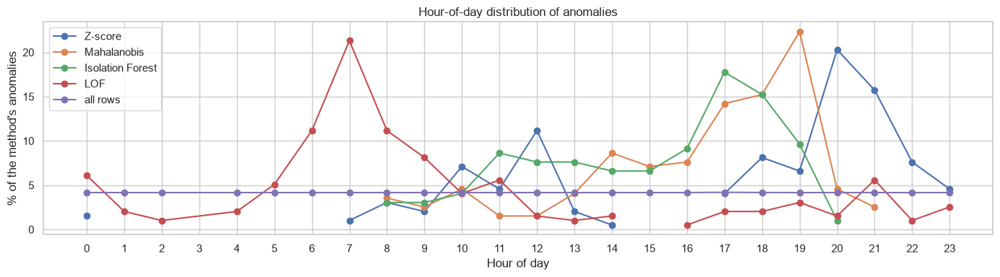

Share of anomalies between 17:00 and 22:59: {'Z-score': 62.4, 'Mahalanobis': 58.9, 'Isolation Forest': 43.7, 'LOF': 15.2, 'all rows': 25.0}


In [45]:
hour_share = pd.DataFrame({m: meta.loc[flags[m], "hour"].value_counts(normalize=True) for m in METHODS})
hour_share["all rows"] = meta["hour"].value_counts(normalize=True)
fig, ax = plt.subplots(figsize=(14, 4))
hour_share.sort_index().mul(100).plot(ax=ax, marker="o")
ax.set_xlabel("Hour of day")
ax.set_ylabel("% of the method's anomalies")
ax.set_xticks(range(24))
ax.set_title("Hour-of-day distribution of anomalies")
plt.tight_layout()
plt.show()
print("Share of anomalies between 17:00 and 22:59:",
      (hour_share.loc[17:22].sum() * 100).round(1).to_dict())

### 6.3 Sensitivity to scaling, dimensionality and noise

A single helper re-runs all four detectors on a modified input and reports the Jaccard overlap of the new top-1% set with the baseline. Four stress tests are applied:

1. **Scaling:** raw units instead of standardised features.
2. **Dimensionality, fewer dimensions:** only the first $k$ principal components.
3. **Dimensionality, more dimensions:** extra irrelevant Gaussian noise features appended.
4. **Noise robustness:** Gaussian measurement noise added to every feature.

Each detector's hyperparameters are unchanged from Section 5.

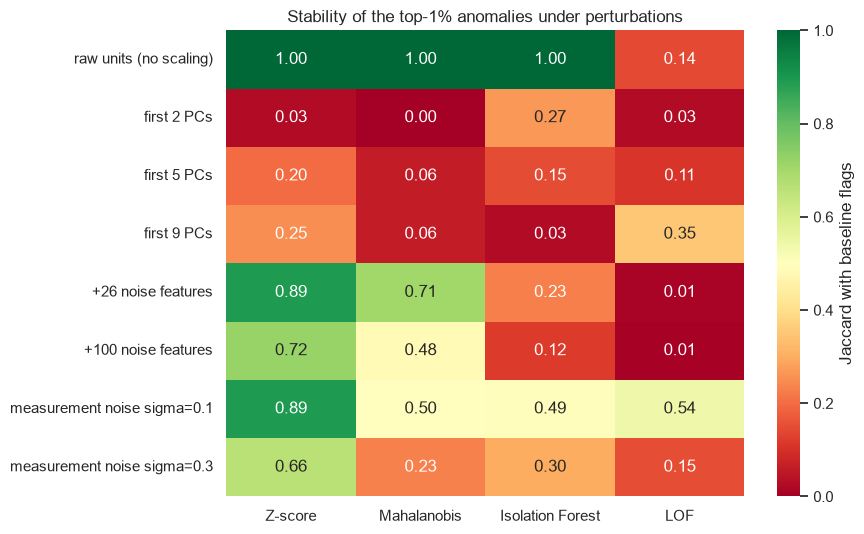

,Z-score,Mahalanobis,Isolation Forest,LOF
raw units (no scaling),1.000,1.000,1.000,0.140
first 2 PCs,0.030,0.000,0.270,0.030
first 5 PCs,0.200,0.060,0.150,0.110
first 9 PCs,0.250,0.060,0.030,0.350
+26 noise features,0.890,0.710,0.230,0.010
+100 noise features,0.720,0.480,0.120,0.010
measurement noise sigma=0.1,0.890,0.500,0.490,0.540
measurement noise sigma=0.3,0.660,0.230,0.300,0.150


In [46]:
DETECTORS = {
    "Z-score": lambda D: np.abs((D - D.mean(0)) / D.std(0)).max(axis=1),
    "Mahalanobis": lambda D: EmpiricalCovariance().fit(D).mahalanobis(D),
    "Isolation Forest": lambda D: -IsolationForest(n_estimators=300, random_state=RANDOM_STATE,
                                                   n_jobs=-1).fit(D).score_samples(D),
    "LOF": lambda D: -LocalOutlierFactor(n_neighbors=LOF_K).fit(D).negative_outlier_factor_,
}

def stress_test(D):
    """Jaccard overlap between the top-1% flags on D and the baseline flags, per detector."""
    return {m: jaccard(top_flags(detect(np.asarray(D, dtype=float))), flags[m].to_numpy())
            for m, detect in DETECTORS.items()}

stress = {"raw units (no scaling)": stress_test(X_raw.to_numpy())}
for k in (2, 5, N_PCA):
    stress[f"first {k} PCs"] = stress_test(Z_all[:, :k])
for n_noise in (26, 100):
    stress[f"+{n_noise} noise features"] = stress_test(np.hstack([X, rng.standard_normal((len(X), n_noise))]))
for sigma in (0.1, 0.3):
    stress[f"measurement noise sigma={sigma}"] = stress_test(X + rng.normal(0, sigma, X.shape))

stress = pd.DataFrame(stress).T
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(stress, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "Jaccard with baseline flags"})
ax.set_title("Stability of the top-1% anomalies under perturbations")
plt.tight_layout()
plt.show()
display(stress.round(2))

### 6.4 Runtime and scalability

The four detectors are timed on growing subsamples of the data. On a log–log plot, the slope approximates the empirical complexity exponent.

method,Isolation Forest,LOF,Mahalanobis,Z-score
n,,,,
2500,0.690,0.029,0.005,0.001
5000,0.806,0.073,0.004,0.003
10000,0.958,0.207,0.013,0.007
19735,1.572,0.721,0.020,0.015


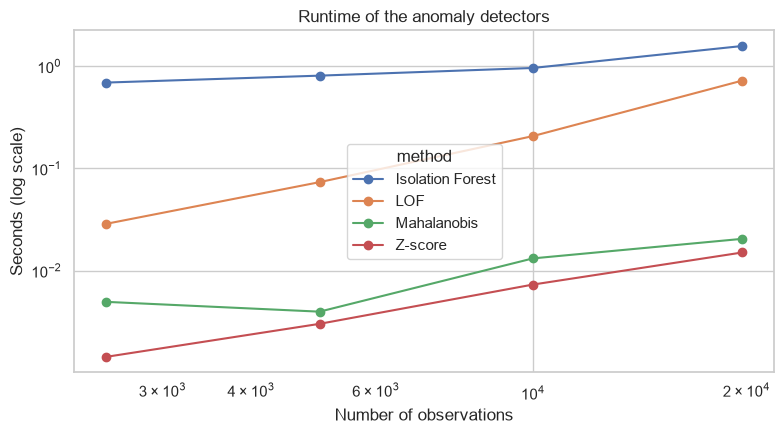

Empirical scaling exponent (time ~ n^slope): {'Isolation Forest': np.float64(0.38), 'LOF': np.float64(1.55), 'Mahalanobis': np.float64(0.79), 'Z-score': np.float64(1.15)}


In [47]:
runtime = []
for n in (2500, 5000, 10000, len(X)):
    D = X[rng.choice(len(X), size=n, replace=False)]
    for method, detect in DETECTORS.items():
        start = time.perf_counter()
        detect(D)
        runtime.append({"n": n, "method": method, "seconds": time.perf_counter() - start})
runtime = pd.DataFrame(runtime).pivot(index="n", columns="method", values="seconds")
display(runtime.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
runtime.plot(ax=ax, marker="o", logx=True, logy=True)
ax.set_xlabel("Number of observations")
ax.set_ylabel("Seconds (log scale)")
ax.set_title("Runtime of the anomaly detectors")
plt.tight_layout()
plt.show()

slopes = {m: np.polyfit(np.log(runtime.index), np.log(runtime[m]), 1)[0] for m in runtime}
print("Empirical scaling exponent (time ~ n^slope):", {m: round(s, 2) for m, s in slopes.items()})

### 6.5 Discussion of the comparison

**Agreement is low.**

- **Overlap of flags.** Of 750 rows flagged by at least one method, 30 are flagged by exactly two methods and just 4 by three. No row is flagged by all four. The pairwise Jaccard indices are at most 0.05.
- **Full rankings.** The three *global* methods (z-score, Mahalanobis, Isolation Forest) have moderately to strongly correlated rankings (Spearman 0.58–0.78). Their disagreement concerns mainly *which* borderline points cross the 1% line. LOF's ranking is almost unrelated to the others (0.10–0.17): it measures a different property.
- **Consensus anomalies.** The four are all plausible evening events:
  - two consecutive readings on 20 January, 19:40–19:50, with lights and appliances at their peak and a cold office;
  - two readings with unusually high kitchen humidity (`RH_1`) at 19:00 and 21:10, consistent with cooking steam.

**Method-specific anomalies reflect each method's definition.**

| Method | Dominant drivers of its unique anomalies | What it "means" by anomaly |
|---|---|---|
| Z-score (max \|z\|) | `RH_5` (showers), `lights` | extreme value in a single sensor |
| Mahalanobis | `RH_1`, `RH_out`, `RH_6` floor (46% of its flags) | unusual *combination* of values |
| Isolation Forest | temperatures, `RH_1`; `RH_6` floor (32%) | point at the edge of the joint range |
| LOF | `Visibility`, `Windspeed`, `log_Appliances` | point unlike its *local* (temporal) neighbourhood |

- **Timing.** 59–62% of the z-score and Mahalanobis anomalies fall between 17:00 and 23:00, compared with 25% of all rows. These methods track the **household's evening routine**. LOF anomalies are, if anything, *under*-represented in the evening (15%): they are driven by weather interpolation rather than by occupant activity.
- **Where the known artifact ends up.** The `RH_6` sensor floor is picked up by Mahalanobis and Isolation Forest but *not* by LOF.

**Sensitivity to feature scaling.** Measured by the overlap with the standardised baseline:

- **Invariant (Jaccard 1.00):** the z-score and Mahalanobis methods, which standardise internally or are affine-invariant, and Isolation Forest, whose splits are relative to each feature's range.
- **Not invariant: LOF** (0.14). Its Euclidean distances are dominated by the features with the largest numeric spread. In raw units these are the outdoor humidities `RH_6` (SD ≈31%) and `RH_out` (≈15%) and `Visibility` (≈12 km), while temperatures (SD ≈2 °C) barely count.

**Scaling is therefore a modelling decision only for distance-based methods.**

**Sensitivity to dimensionality.**

- **Fewer dimensions.** Projecting onto the first 2–9 principal components changes every method's anomalies almost entirely (Jaccard ≤ 0.35). The anomalies live largely in the discarded low-variance directions.
- **More dimensions.** Appending irrelevant noise features affects the methods very differently:

| Method | +26 noise features | +100 noise features | Why |
|---|---|---|---|
| Z-score | 0.89 | 0.72 | Only rows whose max \|z\| comes from a noise column are affected |
| Mahalanobis | 0.71 | 0.48 | Noise inflates $D^2$ uniformly |
| Isolation Forest | 0.23 | 0.12 | Most random splits are wasted on irrelevant features |
| LOF | 0.01 | 0.01 | Distance concentration: every neighbourhood changes |

**Robustness to measurement noise.**

- **Small noise** ($\sigma=0.1$ SD). The z-score method is the most robust (0.89), and the others retain about half of their anomalies.
- **Larger noise** ($\sigma=0.3$ SD). The retention of Mahalanobis and LOF drops to 0.23 and 0.15.

Methods that depend on fine geometric structure, such as correlations or local densities, are the most fragile.

**Runtime and scalability.** On the full data, all methods run in about a second or less. Their scaling differs, however:

- **Z-score and Mahalanobis:** $O(nd)$ and $O(nd^2)$. They are effectively instantaneous.
- **Isolation Forest:** fitting cost is almost independent of $n$ because of subsampling, while scoring is linear in $n$. It shows a fixed overhead but the best scaling.
- **LOF:** requires a $k$-NN search. Its empirical exponent was ≈1.4–1.7, i.e. super-linear, and this becomes the bottleneck for large $n$ or large $d$.

**Interpretability.**

- **Z-score:** fully transparent ("bathroom humidity is 5 SD above normal").
- **Mahalanobis:** interpretable via the covariance ("humidity is high *given* the temperature").
- **Isolation Forest:** gives a score but no native reason. Explanations require post-hoc attribution such as SHAP.
- **LOF:** the least intuitive, because "less dense than its 20 nearest neighbours" is hard to communicate. Its result depends on $k$, and its temporal neighbourhoods are an implicit and hidden modelling choice.

**False positives and false negatives in this household (non-technical summary).**

- **False positive.** The system raises an alarm for something normal, for example a Sunday roast in the oven or a long shower. The occupant receives an alert, checks the appliance and finds nothing wrong. A few of these are harmless, but a daily stream of them teaches people to ignore the alerts.
- **False negative.** The system stays silent when something is really wrong, for example a fridge whose compressor runs continuously or a heater left on in an empty house. Energy and money are wasted until someone happens to notice. With a failing appliance or a humidity problem (mould), the damage can grow unnoticed for weeks.

In this household a missed fault is usually costlier than an unnecessary check, but only as long as false alarms stay rare enough that people keep trusting the system.

**Which results are most meaningful here?** The answer depends on the purpose:

- **Detecting unusual *household behaviour*:** the z-score and Mahalanobis methods, whose anomalies align with evening activity and are interpretable.
- **Finding *sensor faults*:** Mahalanobis and Isolation Forest. Both catch the known `RH_6` artifact, which LOF misses.
- **Detecting *sudden jumps* within the time series:** LOF with a small $k$.

No single detector is universally best, and the low agreement between them is itself the key finding.

## 7. Critical Analysis and Reflection

### 7.1 Distance concentration: why distance-based methods lose meaning in high dimensions

The **curse of dimensionality** can be demonstrated directly. The experiment draws i.i.d. Gaussian points and computes the **relative contrast** between the farthest and nearest neighbour of a query point:

$$
\frac{d_{\max} - d_{\min}}{d_{\min}} .
$$

In low dimensions the nearest neighbour is much closer than the farthest one. As $d$ grows, all pairwise distances converge to the same value, so the contrast tends to 0. "Nearest neighbour", "local density" and "far away" then lose their discriminative power. The real data are included for comparison.

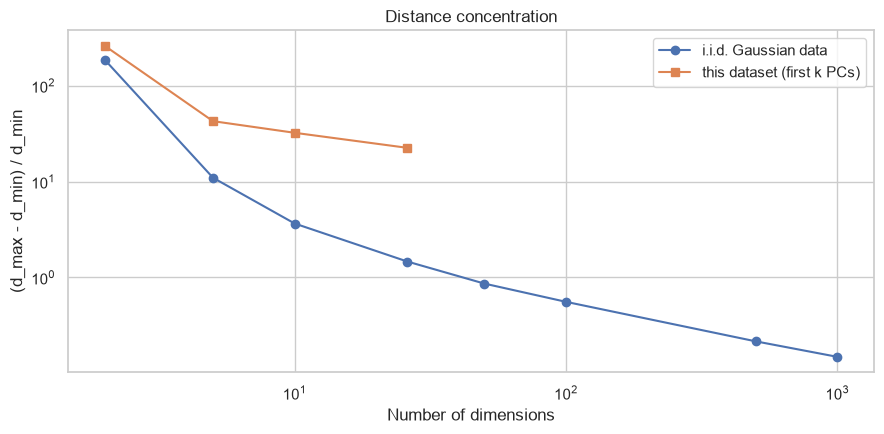

Relative contrast, Gaussian: {2: np.float64(184.8), 5: np.float64(10.95), 10: np.float64(3.65), 26: np.float64(1.46), 50: np.float64(0.86), 100: np.float64(0.56), 500: np.float64(0.22), 1000: np.float64(0.15)}
Relative contrast, real data: {2: np.float64(258.88), 5: np.float64(42.6), 10: np.float64(32.22), 26: np.float64(22.46)}


In [48]:
def relative_contrast(D, n_queries=200):
    """Mean (d_max - d_min) / d_min over random query points."""
    queries = rng.choice(len(D), size=n_queries, replace=False)
    contrasts = []
    for q in queries:
        distances = np.linalg.norm(D - D[q], axis=1)
        distances = distances[distances > 0]
        contrasts.append((distances.max() - distances.min()) / distances.min())
    return np.mean(contrasts)

dims = [2, 5, 10, 26, 50, 100, 500, 1000]
synthetic = [relative_contrast(rng.standard_normal((3000, d))) for d in dims]
real_sample = X[rng.choice(len(X), size=3000, replace=False)]
real_pca = {k: relative_contrast(PCA(n_components=k).fit_transform(real_sample)) for k in (2, 5, 10, 26)}

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.loglog(dims, synthetic, marker="o", label="i.i.d. Gaussian data")
ax.loglog(list(real_pca), list(real_pca.values()), marker="s", label="this dataset (first k PCs)")
ax.set_xlabel("Number of dimensions")
ax.set_ylabel("(d_max - d_min) / d_min")
ax.set_title("Distance concentration")
ax.legend()
plt.tight_layout()
plt.show()
print("Relative contrast, Gaussian:", dict(zip(dims, np.round(synthetic, 2))))
print("Relative contrast, real data:", {k: round(v, 2) for k, v in real_pca.items()})

### 7.2 Noise versus genuine anomaly: an example from this dataset

The cell below takes the observation with the highest consensus (most methods, then highest Isolation Forest score). It plots its three most deviating features over a 24-hour window, so the point can be judged in its temporal context.

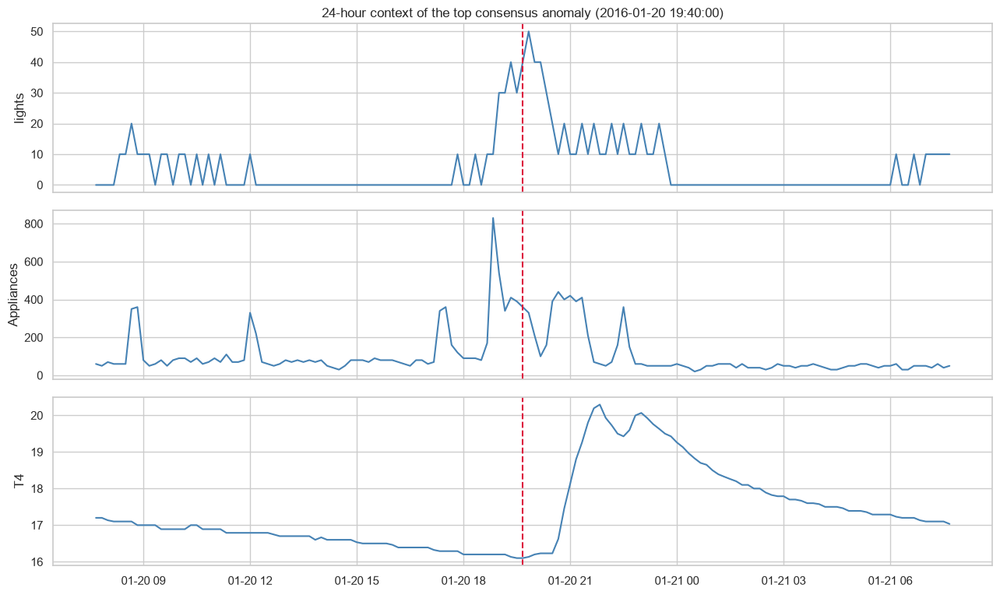

,date,hour,Appliances,n_methods,IF score,LOF,top deviating features (z)
1312,2016-01-20 19:40:00,19,360,3,0.582,1.180,"lights (+4.6), log_Appliances (+2.4), T4 (-2.3)"


In [49]:
example_idx = (explain_rows(consensus_idx if len(consensus_idx) else flags.index[flags.any(axis=1)])
               .sort_values(["n_methods", "IF score"], ascending=False).index[0])
example_time = meta.loc[example_idx, "date"]
top_features = X_df.loc[example_idx].abs().nlargest(3).index.tolist()
raw_names = ["Appliances" if f == "log_Appliances" else f for f in top_features]
window = df[(df["date"] >= example_time - pd.Timedelta(hours=12)) &
            (df["date"] <= example_time + pd.Timedelta(hours=12))]

fig, axes = plt.subplots(len(raw_names), 1, figsize=(13, 2.6 * len(raw_names)), sharex=True)
for ax, feature in zip(np.atleast_1d(axes), raw_names):
    ax.plot(window["date"], window[feature], color="steelblue")
    ax.axvline(example_time, color="crimson", linestyle="--")
    ax.set_ylabel(feature)
np.atleast_1d(axes)[0].set_title(f"24-hour context of the top consensus anomaly ({example_time})")
plt.tight_layout()
plt.show()
display(explain_rows([example_idx]))

**A legitimate anomaly.** The top consensus anomaly, on 20 January at 19:40, was flagged by three of the four methods. The 24-hour window shows what happened:

- after a quiet day, appliances jump to ≈800 Wh around 19:00;
- lights reach their daily maximum;
- the office (`T4`) is at its coldest (≈16 °C);
- shortly afterwards `T4` rises by 4 °C as the room is heated;
- activity stays elevated until about 22:30.

This is a statistically rare *combination* (high activity together with a cold room), but it is a perfectly **legitimate** event: the family coming home on a winter evening, cooking, switching on lights and heating the office. The same applies to the other consensus anomalies (kitchen humidity jumps at dinner time) and to most z-score anomalies (evening showers in `RH_5`).

By contrast, the `RH_6` readings stuck at exactly 1.0% are **noise**, a measurement artifact. They do not describe any physical state of the world. The difference lies in the *cause*:

- **A genuine anomaly** is a rare but real event, which may or may not be interesting. A cooking peak is real but uninteresting; a fridge fault would be real and interesting.
- **Noise** is an error in the recording process, which should be corrected rather than interpreted.

Both look the same to a detector, and only domain knowledge and context, such as the time window above, can tell them apart.

### 7.3 How misleading is the 2D PCA picture?

The final check asks where each method's anomalies fall in the PC1–PC2 plane. It computes the share that lies *inside* the central 95% region of that plane, defined by the 2D Mahalanobis distance. Such points are anomalous in the full space but look perfectly ordinary in the projection.

In [50]:
pc12 = Z_all[:, :2]
d2_pc12 = EmpiricalCovariance().fit(pc12).mahalanobis(pc12)
inside_bulk = d2_pc12 < np.quantile(d2_pc12, 0.95)
hidden = pd.Series({m: 100 * inside_bulk[flags[m]].mean() for m in METHODS},
                   name="% of anomalies hidden in the 2D bulk")
display(hidden.round(1).to_frame())
print(f"PC1 + PC2 retain only {cum_evr[1]:.0%} of the variance.")

,% of anomalies hidden in the 2D bulk
Z-score,89.300
Mahalanobis,62.400
Isolation Forest,33.500
LOF,96.400


PC1 + PC2 retain only 63% of the variance.


### 7.4 Critical discussion

**Why anomaly detection is ill-defined.** An anomaly is only defined relative to a model of "normal", and there are many defensible models:

- extreme single values;
- improbable combinations;
- easy isolation;
- low local density.

Without labels there is no objective way to choose between them. In addition, the flagging threshold (the contamination) is a policy choice rather than a statistical fact. This notebook makes the point concrete: four reasonable detectors, applied to the same data with the same budget, agree on almost nothing (pairwise Jaccard ≤ 0.05), and each disagreement can be explained by its definition.

**The curse of dimensionality.** Its effect on this dataset has three parts:

- **Concentration of distances.** For i.i.d. Gaussian data, the contrast between the nearest and farthest neighbour falls from ≈185 in 2D to ≈1.5 in 26D and ≈0.15 in 1,000D. When all points are almost equally far away, *nearest neighbour* and *local density* lose their meaning.
- **Why this dataset escapes it.** Its contrast is still ≈22 at 26D, because the data have a low *intrinsic* dimension (participation ratio ≈5): distances are driven by a few strong factors. The curse depends on the intrinsic dimension of the data, not on the number of columns.
- **Why noise features still matter.** Adding irrelevant dimensions raises the intrinsic dimension, and LOF's anomalies changed completely after appending 26 noise features. Each additional dimension also adds a chance for an ordinary point to be extreme *somewhere* (the multiple-testing effect of the z-score), and makes the covariance harder to estimate (Mahalanobis).

**Distance-based measures in high dimensions.** For $d$ independent coordinates, the squared distance between two points is a sum of $d$ terms. By the law of large numbers its relative spread shrinks like $1/\sqrt{d}$, so all distances become nearly equal. LOF and k-NN methods then rank points by differences that are dominated by noise. Mitigations include:

- reducing dimensionality first, or selecting features (for example with the feature clustering of Section 4.6);
- using methods that do not rely on distances, such as Isolation Forest;
- using subspace methods.

**Risks of assuming Gaussianity.** Real distributions here are skewed, zero-inflated, bounded and multimodal. The assumption produces errors in both directions:

- **Excess false positives in heavy tails.** The normal right tail of `Appliances` is flagged: $6.7\%$ of rows exceed a nominal 1% $\chi^2$ threshold.
- **Missed anomalies inside the range.** A reading stuck at a *plausible* value is invisible to a z-score, and so is a value that is impossible only for its time of day (a 300 Wh load at 4 a.m.).
- **Distorted multivariate distances.** The covariance itself is inflated by the outliers (masking), which hides the most extreme points.
- **Blindness to multimodality.** When "normal" consists of several regimes (winter and spring), a point *between* regimes can be anomalous yet close to the global mean.

**Misleading projections.** A 2D PCA plot keeps only 63% of the variance, and the discarded 37% is exactly where many anomalies live:

- **Hidden in the bulk.** 96% of the LOF anomalies and 89% of the z-score anomalies fall *inside* the central 95% region of the PC1–PC2 plane. In the plot they look perfectly ordinary.
- **False impressions of outlyingness.** Points that look extreme in 2D may be ordinary in the full space.
- **Artificial groups.** Non-linear embeddings such as t-SNE add another distortion: they create visual clusters (temporal "strands" here) and do not preserve distances between groups.

Visualisations after dimensionality reduction should therefore be treated as a *view* of the results, never as evidence for them.

**Limitations of this analysis.**

- **Dependent observations.** Rows are temporally dependent, and no method used here models time explicitly. A residual-based approach (forecast, then flag large errors) would target contextual anomalies more directly.
- **Limited scope.** There is one household and 4.5 months of data.
- **Unvalidated budget.** The 1% flagging budget is arbitrary and cannot be validated without ground truth.

### 7.5 Ethical considerations

**False alarms.** Every alert consumes attention. When the fraction of alerts that are real (the positive predictive value) is low, operators learn to ignore the system: *alarm fatigue*. At that point a detector with an excellent recall is operationally useless.

Base rates make this unavoidable. If 0.1% of events are real anomalies and a detector has 99% sensitivity and 99% specificity, only about **9% of its alarms are real**. In this dataset, a 1% budget over ~4.5 months equals **~1.5 alerts per day** for one household. That is acceptable for an energy-feedback app but would be intolerable if each alert triggered a technician visit.

**Surveillance.** The same readings that detect a faulty fridge also reveal:

- when residents wake, cook, shower and leave the house;
- when they are away on holiday;
- how many people are home.

The benefits are real: energy savings, fault detection, and wellbeing monitoring for elderly people living alone. But smart-meter data are *behavioural* data. Using them for anything beyond the stated purpose requires informed consent, data minimisation and aggregation. Possible secondary uses include insurance pricing, law enforcement and profiling by landlords.

**Medical applications.**

- **False negative:** a truly abnormal patient is classified as normal. Diagnosis and treatment are delayed, possibly fatally.
- **False positive:** a normal patient is flagged. This causes anxiety, unnecessary tests, radiation exposure and over-treatment.

Because "normal" is learned from a training population, patients from under-represented groups can look anomalous simply for being different from the majority. The threshold should therefore be set *with* clinicians, with explicit costs attached to each error type, and the model should support rather than replace clinical judgement.

**Cybersecurity.** The two errors have very different costs:

- **Missed attack:** it can cause catastrophic, often irreversible damage, such as data exfiltration or ransomware.
- **False alarm on legitimate activity:** the direct cost is usually smaller (an analyst's time, or a temporarily blocked user), but at scale it produces alarm fatigue, which in turn increases the chance of missing the real attack.

Security teams therefore tolerate more false positives than most domains, while triaging alerts by score and context.

**Privacy, bias, fairness and labelling.** Calling a person or behaviour "abnormal" is a normative act disguised as a statistical one. The detectors in this notebook define normality as *similarity to the majority of the training data*. Minority lifestyles are therefore anomalous by construction: night-shift work, religious observance that changes daily routines, disability or unusual household composition.

When such labels drive decisions (credit, insurance, welfare fraud checks, policing), statistical rarity turns into discrimination. Responsible use requires:

- transparency about what is flagged and why;
- human review before any consequential action;
- auditing error rates across groups;
- the right to contest a label;
- collecting and retaining only the data the purpose requires.

## 8. Interactive Dashboard (Bonus)

This section combines the main results into interactive and summary views. Hover over any point to see its timestamp, consumption, cluster and anomaly scores. The views are:

1. PCA plane with the K-Means clusters.
2. PCA plane with the anomaly consensus (number of methods flagging each row), for interactive exploration of anomalies.
3. Heatmap of anomaly frequency by weekday and hour.
4. Pairplot of key features, contrasting consensus anomalies with normal observations.

In [51]:
dashboard = meta.assign(PC1=Z_all[:, 0], PC2=Z_all[:, 1], PC3=Z_all[:, 2],
                        cluster=kmeans_labels.astype(str),
                        n_methods=n_methods.astype(str),
                        IF_score=iforest_scores.round(3), LOF=lof_scores.round(2),
                        Mahalanobis=mahalanobis_sq.round(1))
hover_columns = ["date", "Appliances", "hour", "IF_score", "LOF", "Mahalanobis"]

fig = px.scatter(dashboard, x="PC1", y="PC2", color="cluster", hover_data=hover_columns,
                 render_mode="webgl", opacity=0.5, title=f"PCA plane coloured by K-Means cluster (k={K_CHOSEN})",
                 category_orders={"cluster": [str(c) for c in range(K_CHOSEN)]})
fig.update_traces(marker_size=3)
fig.update_layout(height=550)
fig.show()

**Interactive anomaly exploration.** Points are coloured by how many of the four detectors flag them, and rows flagged by more methods are drawn on top. Clicking legend entries toggles each group on and off.

In [52]:
fig = px.scatter(dashboard.sort_values("n_methods"), x="PC1", y="PC2", color="n_methods",
                 hover_data=hover_columns + ["cluster"], render_mode="webgl",
                 color_discrete_map={"0": "lightgrey", "1": "#fdae61", "2": "#f46d43", "3": "#d73027", "4": "#67001f"},
                 category_orders={"n_methods": ["0", "1", "2", "3", "4"]},
                 title="Anomaly consensus: number of methods flagging each observation")
fig.update_traces(marker_size=4)
fig.update_layout(height=550, legend_title_text="# methods")
fig.show()

**When are anomalies concentrated?** The heatmap shows the percentage of observations in each weekday × hour cell that are flagged by at least two methods.

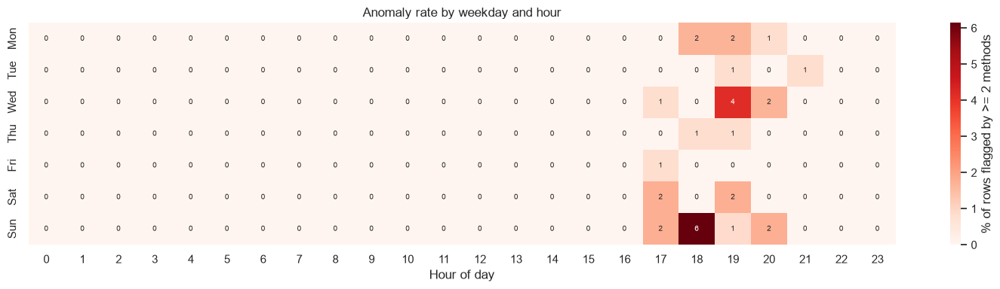

In [53]:
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
anomaly_rate = (meta.assign(anomalous=(n_methods >= 2))
                .pivot_table(index="weekday", columns="hour", values="anomalous", aggfunc="mean") * 100)
anomaly_rate.index = weekday_names
fig, ax = plt.subplots(figsize=(15, 4))
sns.heatmap(anomaly_rate, cmap="Reds", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "% of rows flagged by >= 2 methods"}, ax=ax)
ax.set_title("Anomaly rate by weekday and hour")
ax.set_xlabel("Hour of day")
plt.tight_layout()
plt.show()

**Pairplot.** Five representative features are shown, one from each correlated feature group: consumption, indoor temperature, bathroom humidity, outdoor humidity and outdoor-sensor temperature. Normal rows are a random sample of 1,500, drawn against all consensus anomalies (flagged by at least two methods).

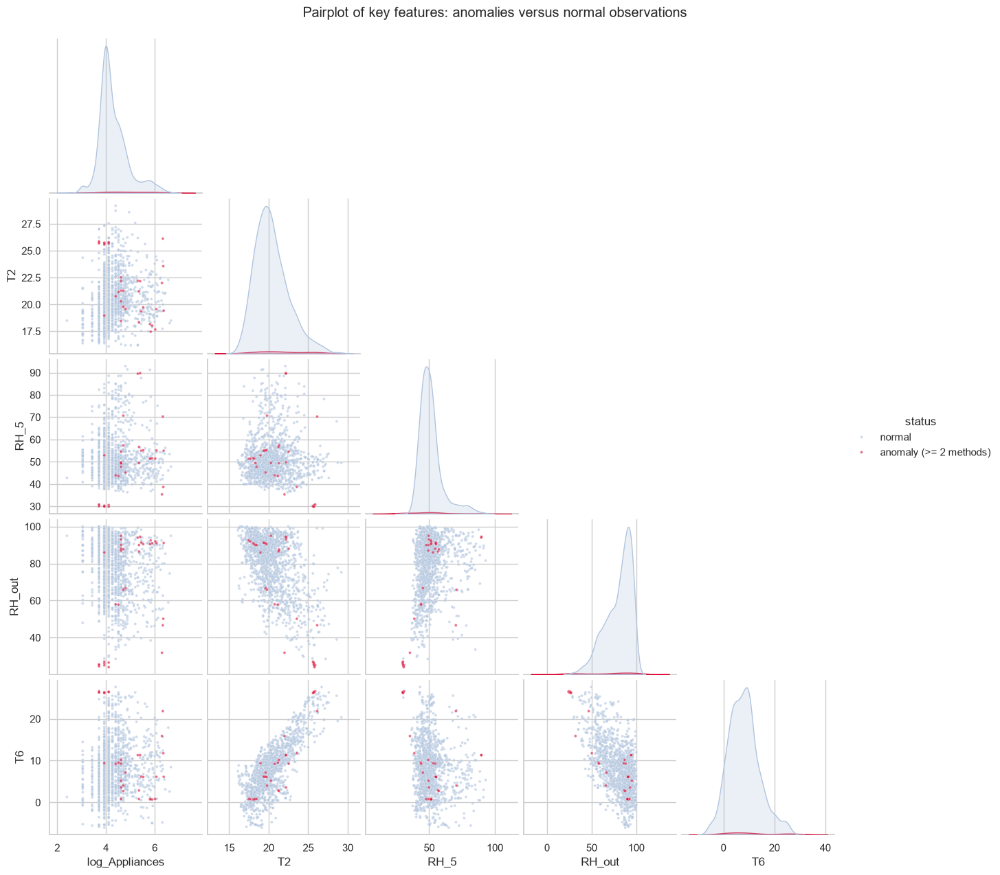

In [54]:
pair_features = ["log_Appliances", "T2", "RH_5", "RH_out", "T6"]
is_anomaly = n_methods >= 2
normal_sample = rng.choice(np.flatnonzero(~is_anomaly), size=1500, replace=False)
pair_rows = np.concatenate([normal_sample, np.flatnonzero(is_anomaly)])
pair_data = X_raw.iloc[pair_rows][pair_features].assign(
    status=np.where(is_anomaly.to_numpy()[pair_rows], "anomaly (>= 2 methods)", "normal"))

grid = sns.pairplot(pair_data, hue="status", corner=True, plot_kws={"s": 8, "alpha": 0.6},
                    palette={"normal": "lightsteelblue", "anomaly (>= 2 methods)": "crimson"})
grid.figure.suptitle("Pairplot of key features: anomalies versus normal observations", y=1.02)
plt.show()

## 9. Conclusions

1. **The data are highly redundant.** Twenty-six features behave like about five effective dimensions: temperature (season), humidity, weather type, occupant activity and synoptic weather. Energy consumption, the variable of practical interest, carries little variance. It surfaces only in the fourth principal component.
2. **There is no strong natural cluster structure.** K-Means and Ward agree on a stable three-regime *seasonal segmentation*: wet winter, cold and dry late winter, warm spring. The silhouette of ≈0.25 and DBSCAN's single dense component show this is a segmentation of a continuum. The clusters describe the climate, not the household's behaviour.
3. **Anomalies depend on their definition.** The four detectors agree on very few observations:
   - **Z-score and Mahalanobis** catch evening activity (showers, cooking, lighting) and broken correlations.
   - **Mahalanobis and Isolation Forest** catch a real sensor artifact (`RH_6` stuck at 1%).
   - **LOF** catches abrupt changes in the local time series and misses the artifact.

   The few consensus anomalies are legitimate evening events rather than faults.
4. **Methodological sensitivity matters as much as the algorithm.** Three factors changed the results substantially:
   - **Scaling:** the only factor that affects LOF but not the other three detectors.
   - **Hyperparameters:** $k$ for LOF, $\varepsilon$ for DBSCAN and the linkage for hierarchical clustering.
   - **Dimensionality and noise:** the neighbourhood-based methods were the most fragile.
5. **Practical recommendation.** For monitoring a home like this one:
   - use an **interpretable global detector** (z-score or robust Mahalanobis) for behaviour;
   - run a **range and consistency check** for sensor faults;
   - model time explicitly for contextual anomalies;
   - set the alert threshold from the cost of false alarms, not from a default contamination value.

**Non-technical summary.** The house's sensors mostly measure the weather and the season, and they measure it many times over. Grouping the data reveals "winter", "cold spell" and "spring", but not different kinds of household behaviour. The unusual moments found by the algorithms are mostly ordinary family life, such as dinner, showers and lights in the evening. The algorithms also exposed one broken sensor. Which moments count as "unusual" depends on the tool used, so any alarm system built on such data needs a clear purpose and human judgement.

## References

1. Candanedo, L. M., Feldheim, V., & Deramaix, D. (2017). Data driven prediction models of energy use of appliances in a low-energy house. *Energy and Buildings*, 140, 81–97.
2. UCI Machine Learning Repository: *Appliances Energy Prediction* (https://archive.ics.uci.edu/dataset/374).
3. Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation Forest. *IEEE ICDM*, 413–422.
4. Breunig, M. M., Kriegel, H.-P., Ng, R. T., & Sander, J. (2000). LOF: Identifying density-based local outliers. *ACM SIGMOD*, 93–104.
5. Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *KDD*, 226–231.
6. Beyer, K., Goldstein, J., Ramakrishnan, R., & Shaft, U. (1999). When is "nearest neighbor" meaningful? *ICDT*, 217–235.
7. van der Maaten, L., & Hinton, G. (2008). Visualizing data using t-SNE. *JMLR*, 9, 2579–2605.